# Brain Bleed Detection on Head CT — Kaggle Optimized

**A multi-label deep-learning baseline for detecting intracranial hemorrhage on head CT slices.**

## About this notebook

This notebook builds an end-to-end research prototype using the RSNA Intracranial Hemorrhage Detection dataset.

For each CT slice, the model predicts six outputs:

- **any** hemorrhage
- **epidural**
- **intraparenchymal**
- **intraventricular**
- **subarachnoid**
- **subdural**

A slice may contain more than one subtype, so this is a **multi-label classification** task with six sigmoid outputs.

| Item | Implementation |
|---|---|
| Dataset | RSNA Intracranial Hemorrhage Detection (Kaggle) |
| Input | DICOM CT slices converted to 3-window RGB images |
| Model | ResNet-50, optionally initialized with ImageNet weights |
| Loss | `BCEWithLogitsLoss` |
| Metrics | Per-label ROC-AUC, sensitivity, specificity, PPV/NPV estimates |
| Split | Patient-level train / validation / test |
| Demo | Interactive real-slice viewer, DICOM upload, Grad-CAM, and synthetic teaching cases |

> **Important:** This notebook is an independent ResNet-50 baseline. It is **not** a reproduction of the original first-place solution, which uses different CNN and sequence-model components.

> **Medical safety:** This is an educational research prototype, not a medical device. Its predictions must not be used for diagnosis, triage, treatment, or clinical decisions. Do not upload identifiable patient data.

## Roadmap

1. Environment and Kaggle data access
2. Load labels and validate them
3. Build a manageable, class-aware subset
4. DICOM metadata and quality checks
5. HU conversion, windowing, and image conversion
6. Patient-level splitting
7. Dataset and DataLoaders
8. ResNet-50 training
9. Evaluation on the held-out test split
10. Limitations and next experiments
11. Interactive Brain Bleed Lab demo

> **Important:** This notebook is a research/educational prototype, not a clinical diagnostic system. The previous ~0.929 test mean ROC-AUC is a baseline on an intentionally enriched slice subset, not a clinical-performance claim. The updated training schedule may improve it, but no metric is guaranteed to increase. Compare runs using the same patient-level split and keep the test set untouched.

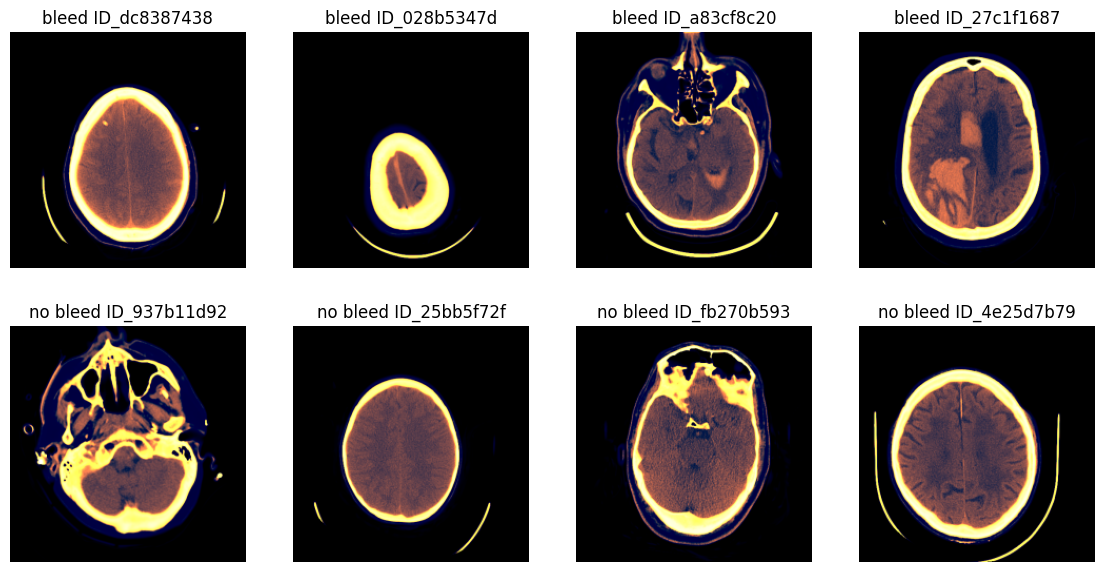

## Part 1: Kaggle environment setup

**Recommended:** Kaggle Notebook with GPU enabled (Notebook Settings → Accelerator → GPU).
1. Click **Add Input** and attach the RSNA 2019 Intracranial Hemorrhage Detection competition dataset.
2. Accept the competition rules on Kaggle before expecting the files to appear.
3. Enable Internet if you need to download ImageNet pretrained weights or create the separate Gradio share page.
4. Run the notebook from top to bottom. Outputs are saved under `/kaggle/working/brain_bleed_outputs`.

This version is Kaggle-first. If the data CSV is not found, verify the attached input and the exact competition dataset name. Do not upload `kaggle.json` into a public notebook.


In [1]:
# Install only the packages this notebook needs.
import sys, subprocess, importlib.util, os, glob, warnings, random, shutil, zipfile, json
from pathlib import Path
from io import BytesIO
from concurrent.futures import ThreadPoolExecutor

def install_if_missing(package, import_name=None):
    import_name = import_name or package
    if importlib.util.find_spec(import_name) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

install_if_missing("pydicom")
install_if_missing("opencv-python-headless", "cv2")
install_if_missing("scikit-learn", "sklearn")
install_if_missing("ipywidgets")
install_if_missing("scipy")
install_if_missing("gradio")

import pydicom
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import GroupShuffleSplit

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IN_COLAB = "google.colab" in sys.modules or importlib.util.find_spec("google.colab") is not None
IN_KAGGLE = Path("/kaggle/input").exists()
if IN_COLAB:
    try:
        from google.colab import output as colab_output
        colab_output.enable_custom_widget_manager()
    except Exception:
        pass

# Kaggle-first paths. Attach the RSNA competition dataset via Add Input.
# If the dataset is not visible under /kaggle/input, confirm competition access and attached input.
DATA_ROOT = Path("/kaggle/input") if IN_KAGGLE else (Path("/content/rsna_data") if IN_COLAB else Path.cwd())
OUT_DIR = Path("/kaggle/working/brain_bleed_outputs") if IN_KAGGLE else (Path("/content/brain_bleed_outputs") if IN_COLAB else Path.cwd() / "brain_bleed_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Training configuration. Reduce batch size if you get CUDA out-of-memory errors.
MAX_POSITIVE_NON_EPIDURAL = 4000
MAX_NEGATIVE = 7000
BATCH_SIZE = 32
EPOCHS_A = 8
EPOCHS_B = 8
USE_IMAGENET_PRETRAINED = True
NUM_WORKERS = 2

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("pydicom:", pydicom.__version__)
print("OpenCV:", cv2.__version__)
print("Environment:", "Colab" if IN_COLAB else ("Kaggle" if IN_KAGGLE else "Local"))
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not detected. ResNet-50 training on CPU will be very slow.")
print("Data root:", DATA_ROOT)
print("Output folder:", OUT_DIR)

# Kaggle note: Internet may be needed only for first-time ImageNet weight download and Gradio share links.
# Enable Internet in Notebook Settings if permitted by your competition/account.


Python: 3.13.16
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
pydicom: 3.0.2
OpenCV: 4.14.0
Environment: Colab
Device: cuda
GPU: Tesla T4
Data root: /kaggle/input
Output folder: /kaggle/working/brain_bleed_outputs


## Part 2: Load labels and clean them

**Goal:** convert the competition's long-format label file into one row per slice with six binary target columns.

- `stage_2_train.csv` contains rows in the form `ID_<sliceID>_<subtype>` with a `Label` of 0 or 1.
- Duplicate IDs are checked for conflicting labels before duplicates are removed.
- The table is pivoted to one row per slice and validated for all six target columns.
- Missing subtype labels are **not** silently converted to negative labels.
- The code prints the actual duplicate count and natural label prevalence from the downloaded CSV.

In [2]:
# Find the RSNA label CSV and its corresponding image folder.
csv_candidates = list(DATA_ROOT.rglob("stage_2_train.csv")) if DATA_ROOT.exists() else []
if not csv_candidates and Path("/kaggle/input").exists():
    csv_candidates = list(Path("/kaggle/input").rglob("stage_2_train.csv"))
if not csv_candidates:
    raise FileNotFoundError(
        "stage_2_train.csv was not found. In Colab, run Part 1.1 and upload kaggle.json; "
        "in Kaggle, attach the RSNA competition dataset as an input."
    )

CSV_PATH = csv_candidates[0]
BASE_DIR = CSV_PATH.parent
print("Labels file:", CSV_PATH)

dcm_candidates = [BASE_DIR / "stage_2_train", BASE_DIR / "stage_2_train_images"]
dcm_candidates += [p for p in BASE_DIR.rglob("stage_2_train") if p.is_dir()]
dcm_candidates += [p for p in BASE_DIR.rglob("stage_2_train_images") if p.is_dir()]
DCM_DIR = next((p for p in dcm_candidates if p.is_dir()), BASE_DIR / "stage_2_train")

raw = pd.read_csv(CSV_PATH)
required = {"ID", "Label"}
if not required.issubset(raw.columns):
    raise ValueError(f"CSV must contain columns {required}; found {raw.columns.tolist()}")

print("Raw rows:", len(raw), "| duplicate IDs:", int(raw["ID"].duplicated().sum()))
duplicate_rows = raw[raw["ID"].duplicated(keep=False)]
if not duplicate_rows.empty:
    conflicting_duplicates = duplicate_rows.groupby("ID")["Label"].nunique().gt(1)
    if conflicting_duplicates.any():
        raise ValueError(f"Conflicting duplicate labels found for {int(conflicting_duplicates.sum())} IDs.")
raw = raw.drop_duplicates(subset="ID", keep="first").copy()
raw[["slice", "type"]] = raw["ID"].astype(str).str.rsplit("_", n=1, expand=True)

EXPECTED_LABELS = ["any", "epidural", "intraparenchymal", "intraventricular", "subarachnoid", "subdural"]
unknown_types = sorted(set(raw["type"]) - set(EXPECTED_LABELS))
if unknown_types:
    raise ValueError(f"Unexpected label types in CSV: {unknown_types}")

labels = raw.pivot(index="slice", columns="type", values="Label").reset_index()
labels.columns.name = None
for col in EXPECTED_LABELS:
    if col not in labels.columns:
        raise ValueError(f"Required label column '{col}' is missing from the competition CSV.")
missing_by_label = labels[EXPECTED_LABELS].isna().sum()
if missing_by_label.sum():
    raise ValueError(
        "Some slice/subtype labels are missing after pivoting. Do not silently treat them as negatives. "
        f"Missing counts: {missing_by_label.to_dict()}"
    )
if not labels[EXPECTED_LABELS].isin([0, 1]).all().all():
    raise ValueError("Label values must be binary 0/1.")
labels[EXPECTED_LABELS] = labels[EXPECTED_LABELS].astype("int8")
subtype_cols = EXPECTED_LABELS[1:]
hierarchy_violations = int(((labels[subtype_cols].max(axis=1) == 1) & (labels["any"] == 0)).sum())
reverse_hierarchy = int(((labels["any"] == 1) & (labels[subtype_cols].sum(axis=1) == 0)).sum())
print("Slices with subtype-positive but any=0:", hierarchy_violations)
print("Slices with any=1 but all five subtypes=0:", reverse_hierarchy)
if hierarchy_violations:
    raise ValueError("Label hierarchy violation: a subtype is positive while 'any' is negative.")
if reverse_hierarchy:
    print("Review these rows: 'any' is positive but all subtype labels are zero. They are retained as supplied.")
labels = labels[["slice"] + EXPECTED_LABELS]

print("One row per slice:", labels.shape)
display(labels.head())
print("Full-data label prevalence:")
display(labels[EXPECTED_LABELS].mean().rename("prevalence").to_frame().T.round(4))
print("Detected DICOM folder:", DCM_DIR, "| exists:", DCM_DIR.exists())

Labels file: /kaggle/input/competitions/rsna-intracranial-hemorrhage-detection/rsna-intracranial-hemorrhage-detection/stage_2_train.csv
Raw rows: 4516842 | duplicate IDs: 24
Slices with subtype-positive but any=0: 0
Slices with any=1 but all five subtypes=0: 0
One row per slice: (752803, 7)


,slice,any,epidural,intraparenchymal,intraventricular,subarachnoid,subdural
0,ID_000012eaf,0,0,0,0,0,0
1,ID_000039fa0,0,0,0,0,0,0
2,ID_00005679d,0,0,0,0,0,0
3,ID_00008ce3c,0,0,0,0,0,0
4,ID_0000950d7,0,0,0,0,0,0


Full-data label prevalence:


,any,epidural,intraparenchymal,intraventricular,subarachnoid,subdural
prevalence,0.1434,0.0042,0.048,0.0348,0.0474,0.0627


Detected DICOM folder: /kaggle/input/competitions/rsna-intracranial-hemorrhage-detection/rsna-intracranial-hemorrhage-detection/stage_2_train | exists: True


## Part 3: Class balance and building a manageable subset

The full RSNA image collection is large. To keep this notebook practical on a Colab/Kaggle GPU, we create a **class-aware subset**:
- all epidural-positive slices (rare subtype),
- up to `MAX_POSITIVE_NON_EPIDURAL` other hemorrhage-positive slices,
- up to `MAX_NEGATIVE` no-hemorrhage slices.

The selected subset is intentionally enriched with positive cases. This changes the natural class prevalence, so metrics such as precision and predictive values must be interpreted carefully. The code prints the actual subset size and prevalence; do not assume a fixed count.

**Sampling caveat:** this subset intentionally oversamples hemorrhage-positive slices (including every epidural-positive slice). It is useful for a manageable experiment, but its class prevalence differs from the competition's natural distribution. Report this clearly; do not interpret its precision/PPV as real-world prevalence performance.


Subset shape: (14145, 7)
Unique slices: 14145
Label prevalence in selected subset:


,any,epidural,intraparenchymal,intraventricular,subarachnoid,subdural
subset_prevalence,0.5051,0.2223,0.14,0.0874,0.1366,0.1749


Selected positive non-epidural: 4000 | selected negatives: 7000


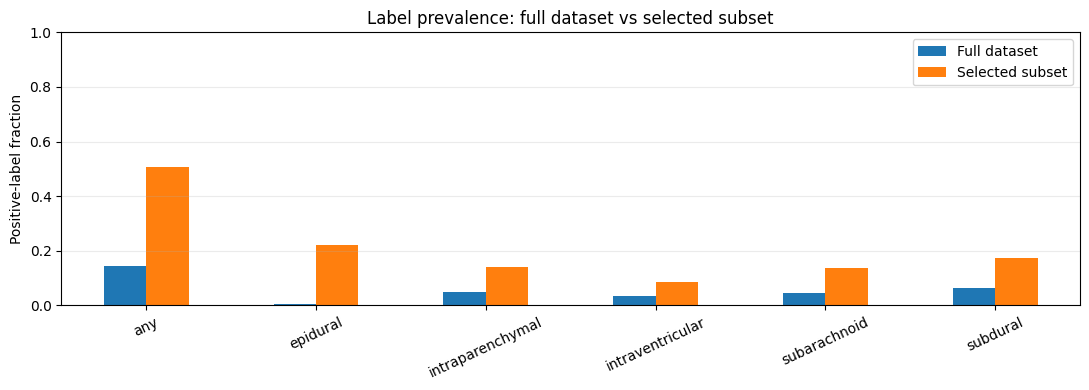

In [3]:
epidural = labels[labels["epidural"] == 1].copy()
other_pos_pool = labels[(labels["any"] == 1) & (labels["epidural"] == 0)]
negative_pool = labels[labels["any"] == 0]

n_other = min(MAX_POSITIVE_NON_EPIDURAL, len(other_pos_pool))
n_negative = min(MAX_NEGATIVE, len(negative_pool))
other_pos = other_pos_pool.sample(n=n_other, random_state=SEED) if n_other else other_pos_pool
negatives = negative_pool.sample(n=n_negative, random_state=SEED) if n_negative else negative_pool

subset = pd.concat([epidural, other_pos, negatives], ignore_index=True)
subset = subset.drop_duplicates("slice").sample(frac=1, random_state=SEED).reset_index(drop=True)

print("Subset shape:", subset.shape)
print("Unique slices:", subset["slice"].nunique())
print("Label prevalence in selected subset:")
display(subset[EXPECTED_LABELS].mean().rename("subset_prevalence").to_frame().T.round(4))
print("Selected positive non-epidural:", len(other_pos), "| selected negatives:", len(negatives))
subset.to_csv(OUT_DIR / "subset_labels.csv", index=False)

# Compare the natural class balance with the intentionally enriched training subset.
balance = pd.DataFrame({
    "Full dataset": labels[EXPECTED_LABELS].mean(),
    "Selected subset": subset[EXPECTED_LABELS].mean()
})
ax = balance.plot(kind="bar", figsize=(11, 4), rot=25)
ax.set_title("Label prevalence: full dataset vs selected subset")
ax.set_ylabel("Positive-label fraction")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()



### 3.1 Make the sampled DICOM slices available

Kaggle Notebooks usually already have the image directory attached. In Colab, the full competition archive may need to be downloaded. This cell extracts **only the sampled slice files** from `stage_2_train.zip`.

The archive download itself is large and may take substantial time and disk space. Selective extraction saves working-disk space after download, but it does not reduce the archive download size. If Colab storage is insufficient, run the notebook in Kaggle with the competition data attached. If you have already extracted the dataset in Google Drive, set `DATA_ROOT` to that folder and rerun the path-discovery cell instead.


In [4]:

from pathlib import Path
import shutil, zipfile

if not DCM_DIR.is_dir():
    possible = list(DATA_ROOT.rglob("stage_2_train")) + list(DATA_ROOT.rglob("stage_2_train_images"))
    DCM_DIR = next((p for p in possible if p.is_dir()), DCM_DIR)

existing_dcm_count = len(list(DCM_DIR.glob("*.dcm"))) if DCM_DIR.is_dir() else 0
if existing_dcm_count < len(subset):
    archive_candidates = list(DATA_ROOT.rglob("stage_2_train.zip"))
    if not archive_candidates and IN_COLAB:
        # Install/configure Kaggle CLI if the CSV was supplied separately from the images.
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kaggle"])
        kaggle_token = Path.home() / ".kaggle" / "kaggle.json"
        if not kaggle_token.exists():
            print("Upload kaggle.json to authorize downloading the RSNA image archive.")
            from google.colab import files
            token_upload = files.upload()
            if "kaggle.json" not in token_upload:
                raise FileNotFoundError("Kaggle API token kaggle.json is required to download stage_2_train.zip.")
            kaggle_token.parent.mkdir(parents=True, exist_ok=True)
            kaggle_token.write_bytes(token_upload["kaggle.json"])
            kaggle_token.chmod(0o600)
        subprocess.check_call([
            "kaggle", "competitions", "download",
            "-c", "rsna-intracranial-hemorrhage-detection",
            "-f", "stage_2_train.zip",
            "-p", str(DATA_ROOT)
        ])
        archive_candidates = list(DATA_ROOT.rglob("stage_2_train.zip"))

    if archive_candidates:
        archive_path = archive_candidates[0]
        DCM_DIR = OUT_DIR / "stage_2_train_selected"
        DCM_DIR.mkdir(parents=True, exist_ok=True)
        wanted = {f"{sid}.dcm" for sid in subset["slice"].astype(str)}
        with zipfile.ZipFile(archive_path, "r") as zf:
            members = [m for m in zf.namelist() if Path(m).name in wanted]
            found = {Path(m).name for m in members}
            missing = wanted - found
            print("Requested slices:", len(wanted), "| found in archive:", len(found), "| missing:", len(missing))
            for member in tqdm(members, desc="Extract sampled DICOMs"):
                target = DCM_DIR / Path(member).name
                if not target.exists():
                    with zf.open(member) as src, open(target, "wb") as dst:
                        shutil.copyfileobj(src, dst)
    else:
        raise FileNotFoundError(
            "DICOM image folder/archive not found. Attach stage_2_train images in Kaggle, "
            "or download stage_2_train.zip with Kaggle API, or set DATA_ROOT to your extracted dataset."
        )

available_ids = {p.stem for p in DCM_DIR.glob("*.dcm")}
subset = subset[subset["slice"].astype(str).isin(available_ids)].reset_index(drop=True)
if len(subset) == 0:
    raise RuntimeError("No sampled DICOM files were found. Check DCM_DIR and the Kaggle dataset version.")
print("DICOM directory:", DCM_DIR)
print("Usable sampled slices:", len(subset))


DICOM directory: /kaggle/input/competitions/rsna-intracranial-hemorrhage-detection/rsna-intracranial-hemorrhage-detection/stage_2_train
Usable sampled slices: 14145


## Part 4: DICOM metadata scan, patient IDs, and quality checks

**Goal:** read DICOM headers first (without pixel data) to check file validity and obtain patient/study identifiers.

Why this matters:
- `PatientID` is needed for patient-level splitting; otherwise slices from the same patient can leak across train and validation.
- `RescaleSlope` and `RescaleIntercept` are needed for HU conversion.
- `WindowCenter` and `WindowWidth` vary, so this notebook uses a documented fixed 3-window representation for consistency.
- Failed headers and missing patient/study identifiers are excluded before splitting and image conversion.

**4.1 Test the header reader on 5 files first**

In [5]:
FIELDS = [
    "PatientID", "StudyInstanceUID", "SeriesInstanceUID",
    "ImagePositionPatient", "RescaleSlope", "RescaleIntercept",
    "WindowCenter", "WindowWidth", "Rows", "Columns",
    "BitsStored", "PixelRepresentation", "Modality",
]

def first_value(x):
    if x is None:
        return None
    try:
        if isinstance(x, (list, tuple, pydicom.multival.MultiValue)):
            return x[0] if len(x) else None
    except Exception:
        pass
    return x

def read_meta(slice_id):
    path = DCM_DIR / f"{slice_id}.dcm"
    try:
        ds = pydicom.dcmread(str(path), stop_before_pixels=True)
        row = {"slice": str(slice_id), "error": None}
        for field in FIELDS:
            value = getattr(ds, field, None)
            if field == "ImagePositionPatient":
                row["PosZ"] = float(value[2]) if value is not None and len(value) >= 3 else np.nan
            elif field in ("WindowCenter", "WindowWidth", "RescaleSlope", "RescaleIntercept"):
                value = first_value(value)
                row[field] = float(value) if value is not None else np.nan
            else:
                row[field] = str(value) if value is not None else None
        return row
    except Exception as exc:
        return {"slice": str(slice_id), "error": repr(exc)}

test = [read_meta(s) for s in subset["slice"].head(5)]
display(pd.DataFrame(test).T)

,0,1,2,3,4
slice,ID_937b11d92,ID_25bb5f72f,ID_fb270b593,ID_4e25d7b79,ID_dc8387438
error,None,None,None,None,None
PatientID,ID_25069181,ID_62b9557f,ID_fa77eeb7,ID_01d9ee7f,ID_57aec053
StudyInstanceUID,ID_2b6e2ee94d,ID_55fa36f133,ID_1f89438e76,ID_cd0fcb3ffa,ID_f1d1dbea35
SeriesInstanceUID,ID_49070f58c1,ID_e03ccd8028,ID_88e0370f88,ID_a924849257,ID_c60fa6e9b9
PosZ,102.93,25.89957,86.525,146.253448,121.798798
RescaleSlope,1.0,1.0,1.0,1.0,1.0
RescaleIntercept,-1024.0,-1024.0,-1024.0,-1024.0,0.0
WindowCenter,40.0,30.0,30.0,30.0,40.0
WindowWidth,80.0,80.0,80.0,80.0,100.0


**4.2 Read the whole subset**

In [6]:
ids = subset["slice"].astype(str).tolist()
with ThreadPoolExecutor(max_workers=NUM_WORKERS) as executor:
    rows_meta = list(tqdm(executor.map(read_meta, ids), total=len(ids), desc="Read DICOM headers"))

meta = pd.DataFrame(rows_meta)
failed_meta = meta["error"].notna()
print("Header read failures:", int(failed_meta.sum()))
if failed_meta.any():
    display(meta.loc[failed_meta, ["slice", "error"]].head())

meta = meta.loc[~failed_meta].copy()
if meta.empty or not {"PatientID", "StudyInstanceUID"}.issubset(meta.columns):
    raise RuntimeError("No usable DICOM metadata was read. Verify DCM_DIR and the DICOM files.")
meta = meta.dropna(subset=["PatientID", "StudyInstanceUID"])
meta = meta.drop_duplicates("slice")
if meta.empty:
    raise RuntimeError("All selected DICOM files are missing PatientID or StudyInstanceUID.")
print("Valid metadata rows:", len(meta))
print("Unique patients:", meta["PatientID"].nunique())
display(meta["RescaleIntercept"].value_counts(dropna=False).head())
display(meta["PixelRepresentation"].value_counts(dropna=False))
meta.to_csv(OUT_DIR / "metadata.csv", index=False)

Read DICOM headers:   0%|          | 0/14145 [00:00<?, ?it/s]

Header read failures: 0
Valid metadata rows: 14145
Unique patients: 7932


RescaleIntercept
-1024.0    13773
-1000.0      210
 0.0         162
Name: count, dtype: int64

PixelRepresentation
1    7985
0    6160
Name: count, dtype: int64

**4.3 Merge labels and metadata into one table (`data`)**

The row order of `data` is the order of the image array built in Part 5, so it must not be re-sorted afterwards.

In [7]:
LABEL_COLS = ["any", "epidural", "intraparenchymal", "intraventricular", "subarachnoid", "subdural"]

data = subset.merge(
    meta[["slice", "PatientID", "StudyInstanceUID", "PosZ", "RescaleSlope", "RescaleIntercept"]],
    on="slice", how="inner", validate="one_to_one"
)
data = data.dropna(subset=["PatientID", "StudyInstanceUID"]).reset_index(drop=True)

print("Merged usable rows:", data.shape)
print("Unique patients:", data["PatientID"].nunique())
display(data.head())
data.to_csv(OUT_DIR / "data_merged.csv", index=False)

Merged usable rows: (14145, 12)
Unique patients: 7932


,slice,any,epidural,intraparenchymal,intraventricular,subarachnoid,subdural,PatientID,StudyInstanceUID,PosZ,RescaleSlope,RescaleIntercept
0,ID_937b11d92,0,0,0,0,0,0,ID_25069181,ID_2b6e2ee94d,102.930000,1.0,-1024.0
1,ID_25bb5f72f,0,0,0,0,0,0,ID_62b9557f,ID_55fa36f133,25.899570,1.0,-1024.0
2,ID_fb270b593,0,0,0,0,0,0,ID_fa77eeb7,ID_1f89438e76,86.525000,1.0,-1024.0
3,ID_4e25d7b79,0,0,0,0,0,0,ID_01d9ee7f,ID_cd0fcb3ffa,146.253448,1.0,-1024.0
4,ID_dc8387438,1,0,0,0,1,0,ID_57aec053,ID_f1d1dbea35,121.798798,1.0,0.0


## Part 5: DICOM visualization and image conversion

**Goal:** convert each selected DICOM slice into a 3-channel image and save the result as a disk-backed NumPy array.

Steps:
1. Decode the DICOM pixel array.
2. Convert stored pixels to Hounsfield Units (HU), including the RSNA near-zero-intercept offset handling.
3. Apply three fixed CT windows (brain, subdural, bone).
4. Resize to `224 × 224`.
5. Save the result as `images_224.npy`.

The three channels represent three different window settings, not RGB color photography.

**5.1 Conversion functions and a visual check on 4 slices**

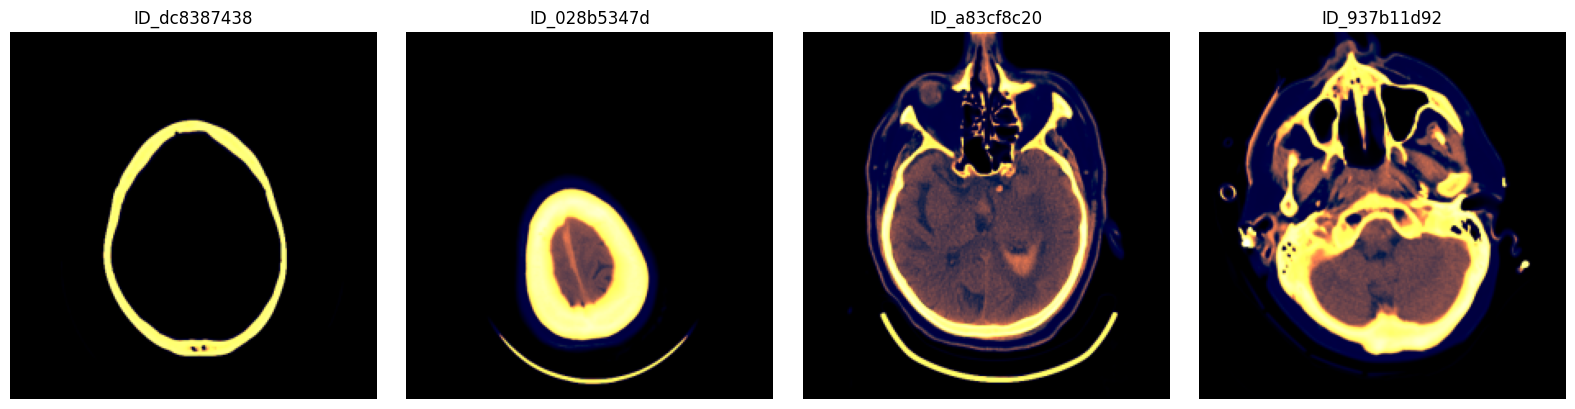

In [8]:
IMG_SIZE = 224
WINDOWS = [(40, 80), (80, 200), (600, 2800)]  # brain / subdural / bone

def dicom_to_hu(ds, pixel_array=None):
    """Convert a single-slice CT DICOM pixel array to Hounsfield Units."""
    raw_pixels = ds.pixel_array if pixel_array is None else pixel_array
    px = np.asarray(raw_pixels).astype(np.int32)
    slope_value = first_value(getattr(ds, "RescaleSlope", 1))
    intercept_value = first_value(getattr(ds, "RescaleIntercept", None))
    slope = float(slope_value) if slope_value is not None else 1.0
    intercept = float(intercept_value) if intercept_value is not None else 0.0

    # RSNA files with an explicitly present near-zero intercept use a +1000 stored-pixel offset.
    if intercept_value is not None and intercept > -100:
        px = px - 1000

    hu = px.astype(np.float32) * slope + intercept

    # Pixel padding is not anatomy. Set it to air so it does not create artificial high-contrast borders.
    padding_value = first_value(getattr(ds, "PixelPaddingValue", None))
    padding_limit = first_value(getattr(ds, "PixelPaddingRangeLimit", None))
    if padding_value is not None:
        padding_value = int(padding_value)
        if padding_limit is None:
            padding_mask = raw_pixels == padding_value
        else:
            padding_limit = int(padding_limit)
            lo, hi = sorted((padding_value, padding_limit))
            padding_mask = (raw_pixels >= lo) & (raw_pixels <= hi)
        hu[padding_mask] = -1000.0

    return hu

def load_hu(slice_id):
    ds = pydicom.dcmread(str(DCM_DIR / f"{slice_id}.dcm"))
    if str(getattr(ds, "Modality", "CT")).upper() != "CT":
        raise ValueError(f"Expected CT DICOM, got Modality={getattr(ds, 'Modality', None)}")
    pixel_array = np.asarray(ds.pixel_array)
    if pixel_array.ndim != 2:
        raise ValueError(f"Expected a 2D CT slice, got shape {pixel_array.shape}")
    return dicom_to_hu(ds, pixel_array=pixel_array)

def apply_window(hu, center, width):
    if width <= 0:
        raise ValueError("Window width must be positive.")
    low, high = center - width / 2, center + width / 2
    clipped = np.clip(hu, low, high)
    return ((clipped - low) / (high - low) * 255.0).astype(np.uint8)

def hu_to_three_channel(hu, photometric="MONOCHROME2"):
    channels = [apply_window(hu, center, width) for center, width in WINDOWS]
    # DICOM MONOCHROME1 means low values display white; invert after windowing.
    if str(photometric).upper() == "MONOCHROME1":
        channels = [255 - ch for ch in channels]
    image = np.stack(channels, axis=-1)
    return cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)

def to_three_channel(slice_id):
    ds = pydicom.dcmread(str(DCM_DIR / f"{slice_id}.dcm"))
    if str(getattr(ds, "Modality", "CT")).upper() != "CT":
        raise ValueError(f"Expected CT DICOM, got Modality={getattr(ds, 'Modality', None)}")
    hu = dicom_to_hu(ds)
    photometric = getattr(ds, "PhotometricInterpretation", "MONOCHROME2")
    return hu_to_three_channel(hu, photometric=photometric)

# Backwards-compatible name used by the synthetic phantom visualization.
hu_to_model_input = hu_to_three_channel

sample = data[data["any"] == 1].head(3)["slice"].tolist() + data[data["any"] == 0].head(1)["slice"].tolist()
fig, axes = plt.subplots(1, max(len(sample), 1), figsize=(4 * max(len(sample), 1), 4))
axes = np.atleast_1d(axes)
for ax, sid in zip(axes, sample):
    ax.imshow(to_three_channel(sid))
    ax.set_title(str(sid))
    ax.axis("off")
plt.tight_layout()
plt.show()

**5.2 Convert the whole subset (one time)**

In [9]:
OUT_PATH = OUT_DIR / "images_224.npy"
slice_ids = data["slice"].astype(str).tolist()

images = np.lib.format.open_memmap(
    OUT_PATH, mode="w+", dtype=np.uint8,
    shape=(len(slice_ids), IMG_SIZE, IMG_SIZE, 3)
)

def convert_one(i):
    try:
        images[i] = to_three_channel(slice_ids[i])
        return None
    except Exception as exc:
        return (i, str(exc))

with ThreadPoolExecutor(max_workers=NUM_WORKERS) as executor:
    conversion_errors = [
        result for result in tqdm(executor.map(convert_one, range(len(slice_ids))),
                                  total=len(slice_ids), desc="Convert DICOM to 3-window images")
        if result is not None
    ]

images.flush()
print("Conversion errors:", len(conversion_errors))
if conversion_errors:
    display(pd.DataFrame(conversion_errors, columns=["row_index", "error"]).head())
    valid_indices = sorted(set(range(len(data))) - {i for i, _ in conversion_errors})
    clean_path = OUT_DIR / "images_224_clean.npy"
    clean_images = np.lib.format.open_memmap(
        clean_path, mode="w+", dtype=np.uint8,
        shape=(len(valid_indices), IMG_SIZE, IMG_SIZE, 3)
    )
    for new_i, old_i in enumerate(tqdm(valid_indices, desc="Keep valid images")):
        clean_images[new_i] = images[old_i]
    clean_images.flush()
    del clean_images, images
    clean_path.replace(OUT_PATH)
    data = data.iloc[valid_indices].reset_index(drop=True)

images = np.load(OUT_PATH, mmap_mode="r")
assert len(images) == len(data), "Image/data row alignment was broken."
print("Saved image array:", OUT_PATH, "| shape:", images.shape)
data.to_csv(OUT_DIR / "data_after_image_validation.csv", index=False)

Convert DICOM to 3-window images:   0%|          | 0/14145 [00:00<?, ?it/s]

Conversion errors: 0
Saved image array: /kaggle/working/brain_bleed_outputs/images_224.npy | shape: (14145, 224, 224, 3)


**5.3 Sanity check**

The image array must have exactly one image per row of `data`, and the pictures should show a clear skull and brain (no all-black or all-white images).

Images: (14145, 224, 224, 3) | rows: 14145


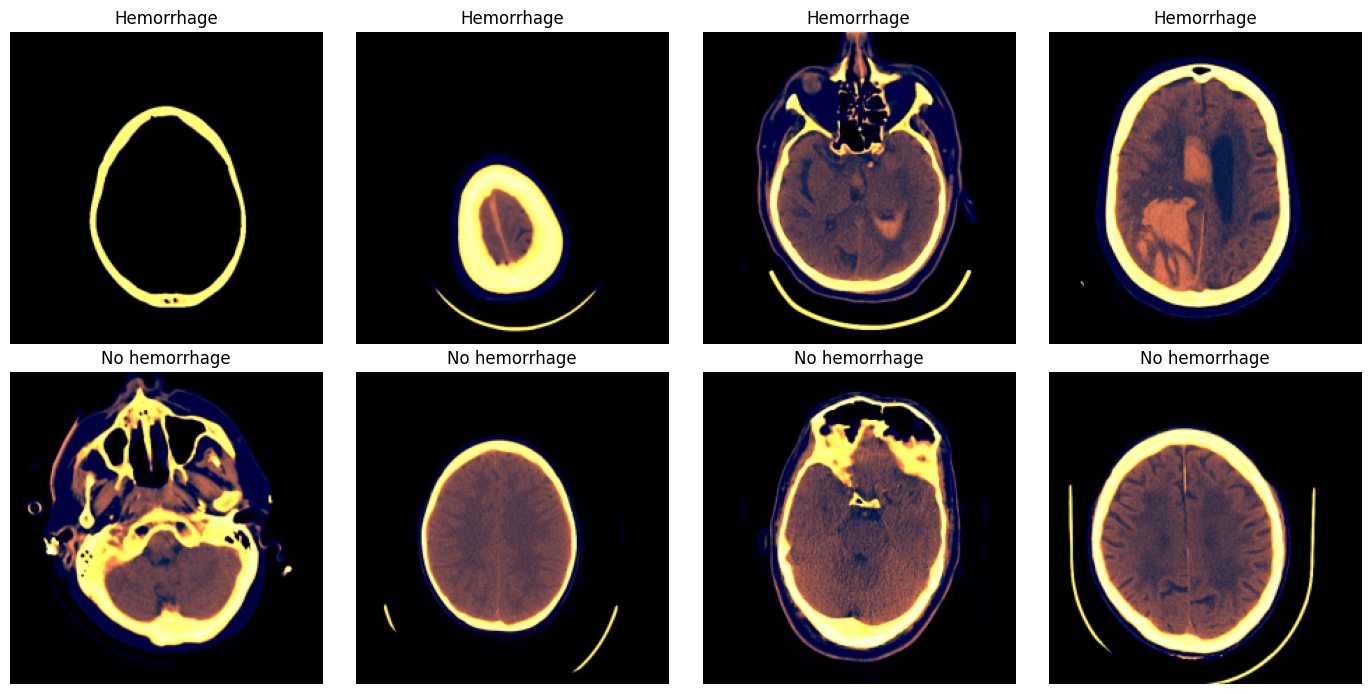

In [10]:
images = np.load(OUT_PATH, mmap_mode="r")
print("Images:", images.shape, "| rows:", len(data))
assert images.shape[0] == len(data)

positive_ids = np.where(data["any"].values == 1)[0][:4]
negative_ids = np.where(data["any"].values == 0)[0][:4]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, i in zip(axes[0], positive_ids):
    ax.imshow(images[i])
    ax.set_title("Hemorrhage")
    ax.axis("off")
for ax, i in zip(axes[1], negative_ids):
    ax.imshow(images[i])
    ax.set_title("No hemorrhage")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Part 6: Patient-level split (train / val / test)

**Never split by slice.** Slices of the same patient look alike, so a slice-level split leaks information from train into validation and inflates every metric.

The split is done with `GroupShuffleSplit` on `PatientID`:
- **70% train**, used to fit the model,
- **15% validation**, used to choose the checkpoint and the decision thresholds,
- **15% test**, touched **once** at the very end.

The three printed overlaps must all be **0**.

In [11]:
# Split by patient, never by individual slice, to reduce patient-level leakage.
groups = data["PatientID"].astype(str).values

gss1 = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
trainval_idx, test_ids = next(gss1.split(data, groups=groups))

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=SEED)
tr_rel, va_rel = next(gss2.split(data.iloc[trainval_idx], groups=groups[trainval_idx]))
train_ids = trainval_idx[tr_rel]
val_ids = trainval_idx[va_rel]

data["split3"] = "train"
data.loc[val_ids, "split3"] = "val"
data.loc[test_ids, "split3"] = "test"

patient_sets = {
    key: set(data.loc[data["split3"] == key, "PatientID"].astype(str))
    for key in ["train", "val", "test"]
}
print("Patient overlap train/val:", len(patient_sets["train"] & patient_sets["val"]))
print("Patient overlap train/test:", len(patient_sets["train"] & patient_sets["test"]))
print("Patient overlap val/test:", len(patient_sets["val"] & patient_sets["test"]))
print("Slice counts:")
display(data["split3"].value_counts().to_frame("slices"))
print("Positive labels by split:")
display(data.groupby("split3")[LABEL_COLS].sum())
data.to_csv(OUT_DIR / "data_with_split.csv", index=False)

Patient overlap train/val: 0
Patient overlap train/test: 0
Patient overlap val/test: 0
Slice counts:


,slices
split3,
train,9975
val,2086
test,2084


Positive labels by split:


,any,epidural,intraparenchymal,intraventricular,subarachnoid,subdural
split3,,,,,,
test,1014,422,256,195,271,342
train,5122,2315,1435,888,1413,1746
val,1009,408,290,153,248,386


## Part 7: Dataset and DataLoader

- The image array is a **memory-mapped NumPy file**, so the full image set does not need to be loaded into RAM at once.
- The Dataset copies one image at a time into a tensor.
- Images are normalized with ImageNet mean and standard deviation because the default model initialization uses ImageNet-pretrained ResNet-50 weights.
- Labels are six binary targets per slice.

In [12]:
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

class ICHDataset(Dataset):
    def __init__(self, image_array, label_array, indices):
        self.images = image_array
        self.labels = label_array
        self.indices = np.asarray(indices, dtype=np.int64)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, k):
        i = int(self.indices[k])
        # Copy from the read-only memory-mapped array before converting to a tensor.
        x = torch.from_numpy(np.array(self.images[i], copy=True)).permute(2, 0, 1)
        y = torch.from_numpy(self.labels[i].copy())
        return x, y

labels_arr = data[LABEL_COLS].values.astype(np.float32)

train_ds = ICHDataset(images, labels_arr, train_ids)
val_ds = ICHDataset(images, labels_arr, val_ids)
test_ds = ICHDataset(images, labels_arr, test_ids)

if min(len(train_ds), len(val_ds), len(test_ds)) == 0:
    raise RuntimeError("Train/validation/test split is empty. Increase the selected dataset size.")

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
    drop_last=False, pin_memory=(device.type == "cuda")
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

def prepare(x):
    x = x.to(device, non_blocking=True).float() / 255.0
    return (x - MEAN) / STD

xb, yb = next(iter(train_loader))
print("Batch:", tuple(xb.shape), "| labels:", tuple(yb.shape), "| device:", device)

Batch: (32, 3, 224, 224) | labels: (32, 6) | device: cuda


## Part 8: Model and training

**Model:** ResNet-50 with its final layer replaced by `Linear(2048, 6)`. By default, the backbone starts from ImageNet weights (`USE_IMAGENET_PRETRAINED=True`); set it to `False` to initialize randomly.

**Two models are trained and later averaged:**
- **Model A:** horizontal flip augmentation.
- **Model B:** stronger GPU augmentation (small rotation, shift, zoom, contrast, brightness, and random flip).

The epoch counts are controlled by `EPOCHS_A` and `EPOCHS_B` in Part 1. The best checkpoint is selected using mean validation ROC-AUC.

Notes:
- Training uses mixed precision on CUDA.
- If you get CUDA out-of-memory errors, lower `BATCH_SIZE` to 16.
- Pretrained weights require Internet access the first time they are downloaded.

**8.1 Augmentation (runs on the GPU)**

In [13]:
def augment(x):
    """Augment normalized tensors, but apply brightness/contrast in the original [0,1] intensity range."""
    b = x.size(0)
    # Undo ImageNet normalization before intensity augmentation.
    x = (x * STD + MEAN).clamp(0, 1)

    angle = (torch.rand(b, device=device) * 2 - 1) * (10 * np.pi / 180)
    scale = 1 + (torch.rand(b, device=device) * 2 - 1) * 0.05
    tx = (torch.rand(b, device=device) * 2 - 1) * 0.05
    ty = (torch.rand(b, device=device) * 2 - 1) * 0.05
    flip = (torch.rand(b, device=device) < 0.5).float() * -2 + 1

    cos = torch.cos(angle) / scale
    sin = torch.sin(angle) / scale
    theta = torch.zeros(b, 2, 3, device=device)
    theta[:, 0, 0] = cos * flip
    theta[:, 0, 1] = -sin
    theta[:, 0, 2] = tx
    theta[:, 1, 0] = sin * flip
    theta[:, 1, 1] = cos
    theta[:, 1, 2] = ty

    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, padding_mode="border", align_corners=False)

    contrast = 1 + (torch.rand(b, device=device) * 2 - 1) * 0.10
    brightness = (torch.rand(b, device=device) * 2 - 1) * 0.05
    x = (x * contrast.view(b, 1, 1, 1) + brightness.view(b, 1, 1, 1)).clamp(0, 1)
    return (x - MEAN) / STD


**8.2 Training helpers**

In [14]:
def predict(model, loader):
    model.eval()
    probabilities, targets = [], []
    with torch.no_grad():
        for x, y in loader:
            x = prepare(x)
            with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
                logits = model(x)
            probabilities.append(torch.sigmoid(logits.float()).cpu().numpy())
            targets.append(y.numpy())
    if not probabilities:
        raise RuntimeError("Prediction loader is empty.")
    return np.concatenate(probabilities), np.concatenate(targets)

def safe_auc(y_true, y_score):
    y_true = np.asarray(y_true)
    if np.unique(y_true).size < 2:
        return np.nan
    return float(roc_auc_score(y_true, y_score))

def mean_auc(y_true, y_score):
    scores = [safe_auc(y_true[:, j], y_score[:, j]) for j in range(y_true.shape[1])]
    return float(np.nanmean(scores)) if np.isfinite(scores).any() else np.nan

def build_resnet50():
    if USE_IMAGENET_PRETRAINED:
        try:
            weights = torchvision.models.ResNet50_Weights.DEFAULT
            model = torchvision.models.resnet50(weights=weights)
            print("Loaded ImageNet pretrained ResNet-50 weights.")
        except Exception as exc:
            raise RuntimeError(
                "Could not download/load ImageNet weights. Enable Internet in Colab/Kaggle, "
                "or set USE_IMAGENET_PRETRAINED=False in Part 1."
            ) from exc
    else:
        model = torchvision.models.resnet50(weights=None)
        print("Initialized ResNet-50 from random weights.")
    model.fc = nn.Linear(model.fc.in_features, len(LABEL_COLS))
    return model.to(device)

def train_model(save_path, epochs, use_aug):
    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)
    model = build_resnet50()

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=1e-4,
        weight_decay=1e-2 if use_aug else 1e-4
    )
    scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=2e-4, epochs=epochs, steps_per_epoch=len(train_loader),
        pct_start=0.15, anneal_strategy="cos"
    )

    best_auc = -np.inf
    best_state_saved = False
    epochs_without_improvement = 0
    EARLY_STOPPING_PATIENCE = 3

    for epoch in range(epochs):
        model.train()
        running_loss, steps = 0.0, 0

        for x, y in tqdm(train_loader, desc=f"{save_path.stem} | epoch {epoch + 1}/{epochs}"):
            x = prepare(x)
            if use_aug:
                x = augment(x)
            elif torch.rand(1).item() < 0.5:
                x = torch.flip(x, dims=[3])

            y = y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
                logits = model(x)
            loss = criterion(logits.float(), y)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            running_loss += float(loss.item())
            steps += 1

        val_prob, val_true = predict(model, val_loader)
        val_score = mean_auc(val_true, val_prob)
        train_loss = running_loss / max(steps, 1)
        print(f"Epoch {epoch + 1}: train_loss={train_loss:.4f} | val_mean_auc={val_score:.4f}")

        if np.isfinite(val_score) and val_score > best_auc:
            best_auc = val_score
            torch.save(model.state_dict(), save_path)
            best_state_saved = True
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print(f"Early stopping: no validation AUC improvement for {EARLY_STOPPING_PATIENCE} epochs.")
            break

    if not best_state_saved:
        print("Warning: validation AUC was undefined; saving the final epoch weights.")
        torch.save(model.state_dict(), save_path)

    model.load_state_dict(torch.load(save_path, map_location=device))
    print("Best validation mean AUC:", round(best_auc, 4) if np.isfinite(best_auc) else "undefined")
    return model

**8.3 Train model A and model B**

In [15]:
# Train two differently augmented ResNet-50 models for a simple probability ensemble.
model_A = train_model(OUT_DIR / "final_A.pt", epochs=EPOCHS_A, use_aug=False)
model_B = train_model(OUT_DIR / "final_B.pt", epochs=EPOCHS_B, use_aug=True)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 188MB/s] 


Loaded ImageNet pretrained ResNet-50 weights.


final_A | epoch 1/8:   0%|          | 0/312 [00:00<?, ?it/s]

Epoch 1: train_loss=0.4263 | val_mean_auc=0.8697


final_A | epoch 2/8:   0%|          | 0/312 [00:00<?, ?it/s]

... (22 outputs left out)

final_B | epoch 7/8:   0%|          | 0/312 [00:00<?, ?it/s]

Epoch 7: train_loss=0.1079 | val_mean_auc=0.9252


final_B | epoch 8/8:   0%|          | 0/312 [00:00<?, ?it/s]

Epoch 8: train_loss=0.0922 | val_mean_auc=0.9236
Best validation mean AUC: 0.9258


**Training summary**

The training cell prints the loss and validation mean ROC-AUC after every epoch and saves the best checkpoint for each model under `OUT_DIR`. Results depend on the actual Kaggle subset, random seed, GPU, and training configuration; no fixed score is assumed in advance.

## Part 9: Final evaluation on the held-out test split

Run this section **once after training**. Do not tune hyperparameters or thresholds after inspecting the test results.

The evaluation cell computes:
- Per-label ROC-AUC for both models and their probability ensemble.
- 95% confidence intervals for ensemble test AUC using patient-level bootstrap resampling.
- Sensitivity and specificity on the test split using thresholds selected on the validation split.
- Estimated PPV/NPV after adjusting sensitivity and specificity to the prevalence in the full label table. These are prevalence-based estimates, not direct measurements on an external population.

In [16]:
# Generate validation predictions first; thresholds are selected ONLY on validation.
pvA, tv = predict(model_A, val_loader)
pvB, _ = predict(model_B, val_loader)
pv_ens = (pvA + pvB) / 2

# Evaluate the held-out test split once.
ptA, tt = predict(model_A, test_loader)
ptB, _ = predict(model_B, test_loader)
pt_ens = (ptA + ptB) / 2

auc_table = pd.DataFrame({
    "val_A": [safe_auc(tv[:, j], pvA[:, j]) for j in range(6)],
    "val_B": [safe_auc(tv[:, j], pvB[:, j]) for j in range(6)],
    "val_ensemble": [safe_auc(tv[:, j], pv_ens[:, j]) for j in range(6)],
    "test_A": [safe_auc(tt[:, j], ptA[:, j]) for j in range(6)],
    "test_B": [safe_auc(tt[:, j], ptB[:, j]) for j in range(6)],
    "test_ensemble": [safe_auc(tt[:, j], pt_ens[:, j]) for j in range(6)],
}, index=LABEL_COLS)

# Patient-level bootstrap confidence intervals for test ensemble AUC (1000 resamples).
test_df = data.iloc[test_ids].reset_index(drop=True)
patient_indices = test_df.groupby("PatientID").indices
patient_keys = list(patient_indices.keys())
rng = np.random.default_rng(SEED)
bootstrap_rows = []

for _ in range(1000):
    chosen_patients = rng.choice(len(patient_keys), size=len(patient_keys), replace=True)
    sample_idx = np.concatenate([patient_indices[patient_keys[k]] for k in chosen_patients])
    bootstrap_rows.append([
        safe_auc(tt[sample_idx, j], pt_ens[sample_idx, j]) for j in range(6)
    ])

bootstrap_scores = np.asarray(bootstrap_rows, dtype=float)
ci_low, ci_high = [], []
for j in range(6):
    valid = bootstrap_scores[:, j][np.isfinite(bootstrap_scores[:, j])]
    if len(valid):
        ci_low.append(float(np.percentile(valid, 2.5)))
        ci_high.append(float(np.percentile(valid, 97.5)))
    else:
        ci_low.append(np.nan)
        ci_high.append(np.nan)

auc_table["ci_low"] = ci_low
auc_table["ci_high"] = ci_high
auc_table["n_positive_test"] = tt.sum(axis=0).astype(int)

print("Per-label ROC-AUC:")
display(auc_table.round(4))
print("Mean test ensemble AUC:", round(float(np.nanmean(auc_table["test_ensemble"])), 4))

# Estimate operating characteristics using validation-selected thresholds.
full_data_prevalence = labels[LABEL_COLS].mean()
rows = []

def safe_ratio(numerator, denominator):
    return float(numerator / denominator) if denominator else np.nan

for j, name in enumerate(LABEL_COLS):
    if np.unique(tv[:, j]).size >= 2:
        fpr, tpr, candidate_thresholds = roc_curve(tv[:, j], pv_ens[:, j])
        threshold = float(candidate_thresholds[np.argmax(tpr - fpr)])
        if not np.isfinite(threshold) or threshold < 0 or threshold > 1:
            threshold = 0.5
    else:
        threshold = 0.5

    pred = (pt_ens[:, j] >= threshold).astype(int)
    truth = tt[:, j].astype(int)
    tp = int(((pred == 1) & (truth == 1)).sum())
    fn = int(((pred == 0) & (truth == 1)).sum())
    fp = int(((pred == 1) & (truth == 0)).sum())
    tn = int(((pred == 0) & (truth == 0)).sum())

    sensitivity = safe_ratio(tp, tp + fn)
    specificity = safe_ratio(tn, tn + fp)
    prevalence = float(full_data_prevalence[name])

    ppv_den = (sensitivity * prevalence + (1 - specificity) * (1 - prevalence)) if np.isfinite(sensitivity) and np.isfinite(specificity) else np.nan
    npv_den = (specificity * (1 - prevalence) + (1 - sensitivity) * prevalence) if np.isfinite(sensitivity) and np.isfinite(specificity) else np.nan
    ppv = safe_ratio(sensitivity * prevalence, ppv_den) if np.isfinite(ppv_den) else np.nan
    npv = safe_ratio(specificity * (1 - prevalence), npv_den) if np.isfinite(npv_den) else np.nan

    rows.append({
        "label": name, "threshold_from_validation": threshold,
        "sensitivity_test": sensitivity, "specificity_test": specificity,
        "full_dataset_prevalence": prevalence, "PPV_est_at_full_prevalence": ppv,
        "NPV_est_at_full_prevalence": npv, "TP": tp, "FN": fn, "FP": fp, "TN": tn
    })

operating_table = pd.DataFrame(rows).set_index("label")
display(operating_table.round(4))

auc_table.to_csv(OUT_DIR / "final_test_results.csv")
operating_table.to_csv(OUT_DIR / "operating_points.csv")
np.save(OUT_DIR / "test_probs_ensemble.npy", pt_ens)
np.save(OUT_DIR / "test_labels.npy", tt)
print("Saved evaluation files to:", OUT_DIR)

Per-label ROC-AUC:


,val_A,val_B,val_ensemble,test_A,test_B,test_ensemble,ci_low,ci_high,n_positive_test
any,0.9564,0.9621,0.9654,0.9528,0.9546,0.9596,0.9459,0.9702,1014
epidural,0.9025,0.9248,0.9269,0.9271,0.9170,0.9325,0.8923,0.9601,422
intraparenchymal,0.9523,0.9536,0.9571,0.9442,0.9562,0.9570,0.9417,0.9711,256
intraventricular,0.9611,0.9626,0.9681,0.9491,0.9636,0.9628,0.9509,0.9744,195
subarachnoid,0.8743,0.8704,0.8796,0.8788,0.8749,0.8864,0.8565,0.9104,271
subdural,0.8698,0.8814,0.8868,0.8613,0.8814,0.8861,0.8600,0.9118,342


Mean test ensemble AUC: 0.9307


,threshold_from_validation,sensitivity_test,specificity_test,full_dataset_prevalence,PPV_est_at_full_prevalence,NPV_est_at_full_prevalence,TP,FN,FP,TN
label,,,,,,,,,,
any,0.4611,0.8767,0.9159,0.1434,0.6356,0.9780,889,125,90,980
epidural,0.1127,0.8791,0.8562,0.0042,0.0250,0.9994,371,51,239,1423
intraparenchymal,0.0787,0.9062,0.8408,0.0480,0.2229,0.9944,232,24,291,1537
intraventricular,0.1790,0.7949,0.9587,0.0348,0.4098,0.9923,155,40,78,1811
subarachnoid,0.1382,0.7601,0.8323,0.0474,0.1840,0.9859,206,65,304,1509
subdural,0.1642,0.8275,0.7744,0.0627,0.1969,0.9853,283,59,393,1349


Saved evaluation files to: /kaggle/working/brain_bleed_outputs


### 9.1 Additional evaluation for class imbalance
ROC-AUC alone is not enough for an imbalanced medical dataset. This section reports PR-AUC, precision, recall, F1, confusion counts, and validation-only thresholds targeting at least 90% sensitivity. The test set is used only to report final metrics, never to choose thresholds.

In [17]:
# Additional imbalance-aware metrics and sensitivity-oriented operating thresholds.
from sklearn.metrics import average_precision_score, precision_score, recall_score, f1_score, confusion_matrix

def threshold_for_target_sensitivity(y_true, y_score, target_sensitivity=0.90):
    """Choose the highest validation threshold whose sensitivity is at least the requested target."""
    fpr, tpr, thresholds = roc_curve(y_true, y_score)
    valid = np.where((tpr >= target_sensitivity) & np.isfinite(thresholds))[0]
    if len(valid) == 0:
        return 0.0
    # Highest finite threshold among qualifying ROC points is the more conservative qualifying choice.
    return float(np.max(thresholds[valid]))

metric_rows = []
threshold_rows = []
for j, name in enumerate(LABEL_COLS):
    thr_youden = float(operating_table.loc[name, "threshold_from_validation"])
    thr_90 = threshold_for_target_sensitivity(tv[:, j], pv_ens[:, j], 0.90)
    pred = (pt_ens[:, j] >= thr_youden).astype(int)
    metric_rows.append({
        "label": name,
        "test_PR_AUC": float(average_precision_score(tt[:, j], pt_ens[:, j])),
        "test_precision_at_youden": float(precision_score(tt[:, j], pred, zero_division=0)),
        "test_recall_at_youden": float(recall_score(tt[:, j], pred, zero_division=0)),
        "test_F1_at_youden": float(f1_score(tt[:, j], pred, zero_division=0)),
        "TN": int(confusion_matrix(tt[:, j], pred, labels=[0,1])[0,0]),
        "FP": int(confusion_matrix(tt[:, j], pred, labels=[0,1])[0,1]),
        "FN": int(confusion_matrix(tt[:, j], pred, labels=[0,1])[1,0]),
        "TP": int(confusion_matrix(tt[:, j], pred, labels=[0,1])[1,1]),
    })
    threshold_rows.append({"label": name, "youden_threshold": thr_youden, "threshold_for_90pct_val_sensitivity": thr_90})

imbalance_metrics = pd.DataFrame(metric_rows).set_index("label")
sensitivity_thresholds = pd.DataFrame(threshold_rows).set_index("label")
print("Imbalance-aware test metrics (thresholds selected on validation):")
display(imbalance_metrics.round(4))
print("Validation thresholds targeting >=90% sensitivity:")
display(sensitivity_thresholds.round(4))

# Model-specific validation thresholds prevent comparing Model A/B at an arbitrary 0.50 threshold.
def thresholds_from_validation(y_true, y_score, target_sensitivity=0.90):
    return np.array([threshold_for_target_sensitivity(y_true[:, j], y_score[:, j], target_sensitivity)
                     for j in range(y_true.shape[1])], dtype=float)

DEMO_THRESHOLDS = {
    "Model A": thresholds_from_validation(tv, pvA, 0.90),
    "Model B": thresholds_from_validation(tv, pvB, 0.90),
    "Ensemble (A + B)": thresholds_from_validation(tv, pv_ens, 0.90),
}
DEMO_THR = DEMO_THRESHOLDS["Ensemble (A + B)"]
print("Demo thresholds are validation-only and target >=90% sensitivity. They may increase false positives.")

imbalance_metrics.to_csv(OUT_DIR / "imbalance_metrics.csv")
sensitivity_thresholds.to_csv(OUT_DIR / "sensitivity_thresholds.csv")
np.savez_compressed(OUT_DIR / "validation_predictions.npz", y=tv, model_a=pvA, model_b=pvB, ensemble=pv_ens)
print("Saved extra metrics and validation predictions to:", OUT_DIR)


Imbalance-aware test metrics (thresholds selected on validation):


,test_PR_AUC,test_precision_at_youden,test_recall_at_youden,test_F1_at_youden,TN,FP,FN,TP
label,,,,,,,,
any,0.9619,0.9081,0.8767,0.8921,980,90,125,889
epidural,0.8085,0.6082,0.8791,0.7190,1423,239,51,371
intraparenchymal,0.8227,0.4436,0.9062,0.5956,1537,291,24,232
intraventricular,0.8083,0.6652,0.7949,0.7243,1811,78,40,155
subarachnoid,0.6123,0.4039,0.7601,0.5275,1509,304,65,206
subdural,0.6537,0.4186,0.8275,0.5560,1349,393,59,283


Validation thresholds targeting >=90% sensitivity:


,youden_threshold,threshold_for_90pct_val_sensitivity
label,,
any,0.4611,0.4324
epidural,0.1127,0.1057
intraparenchymal,0.0787,0.0828
intraventricular,0.1790,0.1038
subarachnoid,0.1382,0.0531
subdural,0.1642,0.1097


Demo thresholds are validation-only and target >=90% sensitivity. They may increase false positives.
Saved extra metrics and validation predictions to: /kaggle/working/brain_bleed_outputs


### Results

The next evaluation cell generates the per-label validation/test ROC-AUC table, patient-bootstrap confidence intervals, and validation-selected operating points. These values are calculated from the current run and saved to:

- `final_test_results.csv`
- `operating_points.csv`
- `test_probs_ensemble.npy`
- `test_labels.npy`

Do not copy results from an earlier run into a report. Report the metrics produced by the exact notebook version and split used for your experiment.

## Part 10: Experiments and improvements

After the first valid run, change **one factor at a time** and compare on the validation set. Keep the test split untouched until the final evaluation.

Recommended experiments:
1. Compare the single models with the probability ensemble.
2. Compare ImageNet initialization with random initialization (only if compute allows).
3. Tune batch size, learning rate, and training epochs.
4. Test a larger patient-level subset.
5. Add a 2.5D input using adjacent slices from the same study, sorted by DICOM position.
6. Compare additional backbones such as DenseNet or SE-ResNeXt.
7. Add scan-level aggregation rather than treating every slice as a separate final decision.

**Do not use the held-out test split to select hyperparameters or decision thresholds.**

## Part 11: Limitations and conclusion

Keep these limitations visible in every project presentation:

- **Enriched subset:** positive cases are deliberately oversampled. This changes class prevalence and can make precision / predictive values on the subset misleading.
- **Patient-level split:** reduces leakage between patients, but a single split still has sampling uncertainty.
- **Single-slice baseline:** the current ResNet-50 sees one slice at a time. It does not model the full CT volume or neighboring-slice context.
- **Threshold dependence:** thresholds are selected on the validation split and may not transfer to another hospital, scanner, or population.
- **No external validation:** this notebook does not establish performance on independent hospitals or clinical cohorts.
- **Synthetic cases:** the phantom generator is a teaching visualization only; it is not a realistic substitute for real DICOM scans.
- **Not a medical device:** outputs are research predictions only and must never be used for diagnosis or patient management.

**Conclusion:** this notebook provides a reproducible starting pipeline for multi-label CT-slice classification, with DICOM preprocessing, patient-level splitting, two ResNet-50 runs, evaluation, Grad-CAM, and an interactive educational demo. The actual performance must be taken from the current run's evaluation outputs.

**Data use:** follow the RSNA competition terms. Do not redistribute raw DICOM files or identifiable patient information.

- **Architecture:** this notebook trains an independent ResNet-50 ensemble. It is not an exact reproduction of the linked repository's DenseNet/SE-ResNeXt/sequence architecture.
- **Slice-level task:** the current model analyzes individual 2D slices, not full patient CT volumes or study-level context.
- **Prevalence shift:** training/evaluation subset sampling is enriched; natural-prevalence PPV/NPV estimates are approximations and require external validation.
- **Threshold trade-off:** targeting 90% validation sensitivity usually lowers specificity and can increase false alarms. The chosen threshold is not a clinical cutoff.
- **DICOM edge cases:** validate rescale slope/intercept, pixel padding, signedness, and MONOCHROME1/MONOCHROME2 behavior on each external source before claiming compatibility.
- **External validation:** the held-out split comes from the same competition dataset. A separate hospital/scanner cohort is required to assess generalization.


## Part 12: Interactive demo — Brain Bleed Lab

The demo has three experiences:

1. **Synthetic teaching cases:** adjust a simplified phantom and inspect the model response. These are deliberately artificial and out-of-distribution; do not interpret their probabilities as clinical performance.
2. **Real held-out slices:** browse real labeled slices from the internal patient-level test split, with model probabilities and Grad-CAM.
3. **Upload a DICOM:** load one local 2D CT DICOM slice and run the same preprocessing and model inference pipeline. No patient identifiers are displayed.

The dashboard requires the trained `model_A` and `model_B` checkpoints. `ipywidgets` must be enabled in the notebook frontend.

> **Safety notice:** the demo is for education and software demonstration only. It is not a diagnostic tool, does not provide medical advice, and must not be used to make clinical decisions. Upload only de-identified data that you are authorized to use.

**12.1 Synthetic head-CT phantom generator**

This creates simplified, hand-designed HU images for explaining the interface. The synthetic cases are not medical images and are not used for model training or evaluation.

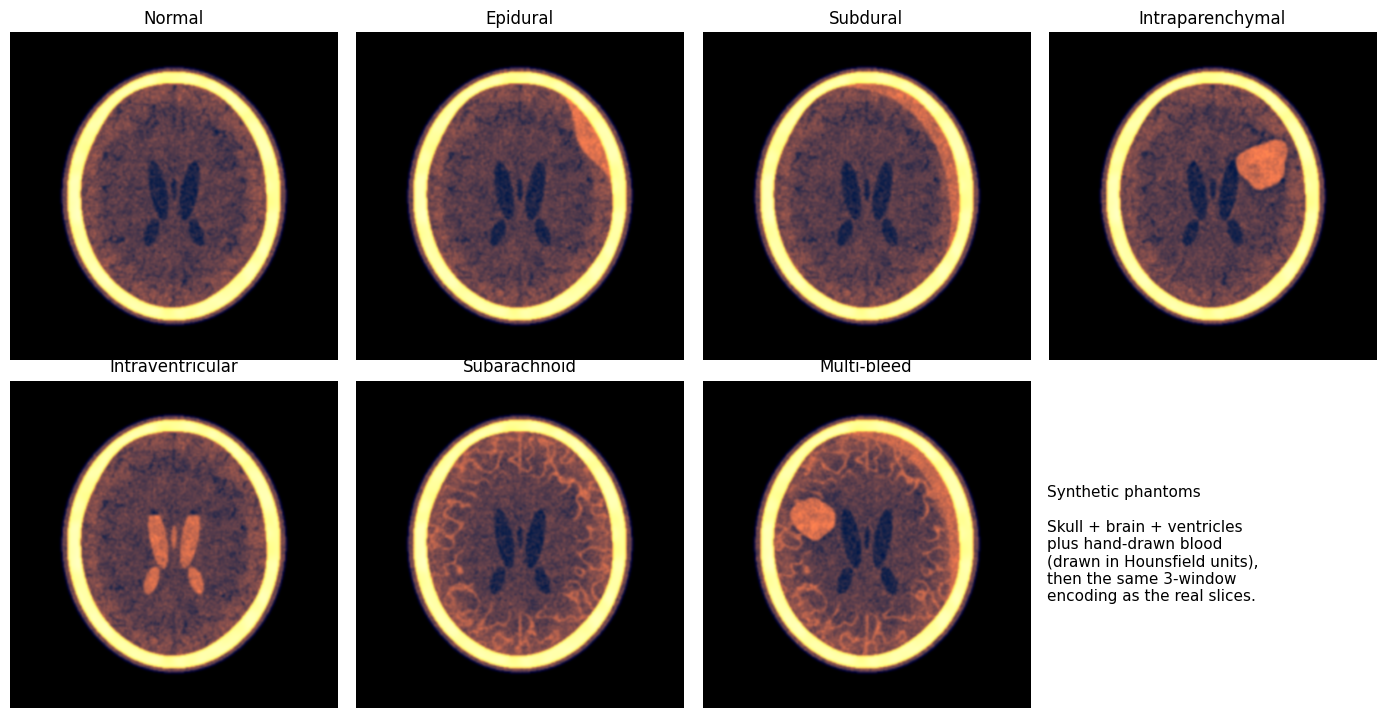

In [18]:
from scipy.ndimage import gaussian_filter

# ---------- Synthetic head-CT phantom, drawn directly in Hounsfield units ----------
SYN_N, SYN_EXT = 384, 1.25                      # internal grid; the frame spans [-1.25, 1.25]
_Y, _X = np.mgrid[-SYN_EXT:SYN_EXT:complex(SYN_N), -SYN_EXT:SYN_EXT:complex(SYN_N)]

KINDS = ["epidural", "intraparenchymal", "intraventricular", "subarachnoid", "subdural"]
PRETTY = {"any": "Any bleed", "epidural": "Epidural", "intraparenchymal": "Intraparenchymal",
          "intraventricular": "Intraventricular", "subarachnoid": "Subarachnoid", "subdural": "Subdural"}

def _smooth01(t):
    t = np.clip(t, 0.0, 1.0)
    return t * t * (3 - 2 * t)

def _ell(cx, cy, ax, ay, rot=0.0):
    """Squared elliptical radius around (cx, cy); < 1 means inside."""
    c, s = np.cos(rot), np.sin(rot)
    dx, dy = _X - cx, _Y - cy
    u, v = (dx * c + dy * s) / ax, (-dx * s + dy * c) / ay
    return u * u + v * v

def make_phantom(kinds=(), size=0.5, density=70.0, angle=35.0, noise=5.0, seed=0):
    """Return a dict with the HU image, the true lesion mask and the 6-vector of true labels."""
    rng = np.random.default_rng(int(seed))
    field = lambda sigma: (lambda f: f / f.std())(gaussian_filter(rng.standard_normal((SYN_N, SYN_N)), sigma))
    kinds = set(kinds)

    # --- anatomy: scalp, skull, brain (grey/white), sulci, ventricles, falx ---
    sx, sy = 1 + 0.06 * (rng.random() - 0.5), 1 + 0.06 * (rng.random() - 0.5)
    R_scalp = np.sqrt(_ell(0, 0, 0.86 * sx, 0.97 * sy))
    R_out = np.sqrt(_ell(0, 0, 0.80 * sx, 0.92 * sy))
    R_in = np.sqrt(_ell(0, 0, 0.72 * sx, 0.84 * sy)) * (1 + 0.012 * field(30))
    brain = R_in < 1

    hu = np.full((SYN_N, SYN_N), -1000.0)
    hu[R_scalp < 1] = 35.0
    skull = (R_out < 1) & ~brain
    hu[skull] = 1050 + 120 * field(6)[skull]

    grey = _smooth01((R_in - 0.72) / 0.18)
    tissue = 28 + 12 * grey + 2.2 * field(5)

    band = _smooth01((R_in - 0.55) / 0.12) * (1 - _smooth01((R_in - 0.96) / 0.04))
    n_sulc = field(4.5)
    sulci = np.exp(-(n_sulc / 0.16) ** 2) * band
    sulci_wide = np.exp(-(n_sulc / 0.30) ** 2) * band      # wider lines, used when blood fills the sulci
    fissure = np.exp(-(_X / 0.010) ** 2) * _smooth01((np.abs(_Y) - 0.35) / 0.1) * band
    tissue = tissue - 22 * sulci - 12 * fissure
    hu[brain] = tissue[brain]

    V = np.zeros_like(hu, dtype=bool)
    for sgn in (-1, 1):
        V |= _ell(sgn * 0.12, -0.04, 0.065, 0.23, sgn * 0.18) < 1
        V |= _ell(sgn * 0.17, 0.28, 0.05, 0.11, -sgn * 0.35) < 1
    V |= _ell(0, -0.05, 0.02, 0.09) < 1
    V &= brain
    hu[V] = 8.0

    # --- lesions ---
    lesion = np.zeros_like(hu)
    phi = np.arctan2(-_Y / 0.84, _X / 0.72)        # 0 deg = right of the image, +90 deg = top
    depth = 1.0 - R_in                              # distance below the inner skull surface
    adiff = lambda a: (phi - np.deg2rad(a) + np.pi) % (2 * np.pi) - np.pi
    loc = [k for k in ("epidural", "subdural", "intraparenchymal") if k in kinds]
    ang = {k: angle + 120.0 * i for i, k in enumerate(loc)}   # several lesions are spread around the head
    blood = float(density)

    if "epidural" in kinds:                         # biconvex (lens-shaped), sharp edges, bright
        u = adiff(ang["epidural"]) / np.deg2rad(16 + 22 * size)
        t = np.where(np.abs(u) < 1, (0.05 + 0.20 * size) * np.cos(np.pi / 2 * u) ** 2, 0.0)
        m = brain & (depth < t) & (t > 0)
        hu[m] = blood + 3 * field(3)[m]; lesion[m] = 1

    if "subdural" in kinds:                         # thin crescent hugging the brain surface
        u = adiff(ang["subdural"]) / np.deg2rad(35 + 45 * size)
        t = np.where(np.abs(u) < 1, (0.04 + 0.12 * size) * (1 - np.abs(u) ** 2.5), 0.0)
        m = brain & (depth < t) & (t > 0)
        hu[m] = blood - 8 + 3 * field(3)[m]; lesion[m] = 1

    if "intraparenchymal" in kinds:                 # irregular blob inside the brain + dark oedema halo
        a = np.deg2rad(ang["intraparenchymal"])
        cx, cy = 0.46 * np.cos(a), -0.46 * np.sin(a)
        r0 = 0.05 + 0.13 * size
        rho = np.hypot(_X - cx, _Y - cy) / (1 + 0.22 * field(9))
        halo = brain & (rho < r0 * 1.7)
        hu[halo] -= 10 * (1 - _smooth01((rho[halo] / r0 - 1) / 0.7))
        core = brain & (rho < r0)
        hu[core] = blood + 4 * field(3)[core]; lesion[core] = 1

    if "intraventricular" in kinds:                 # blood layering in the dependent part of the ventricles
        y_cut = 0.38 - (0.4 + 0.6 * size) * 0.66
        m = V & (_Y > y_cut)
        hu[m] = blood - 5 + 3 * field(3)[m]; lesion[m] = 1

    if "subarachnoid" in kinds:                     # blood fills the sulci, fissures and cisterns
        m = np.clip(sulci_wide * (0.7 + 0.5 * size) + fissure * (0.6 + 0.6 * size), 0, 1) * brain
        hu = hu * (1 - m) + (blood - 5) * m
        lesion = np.maximum(lesion, (gaussian_filter((m > 0.4).astype(float), 9) > 0.12).astype(float))   # coarse outline, not every sulcus

    # --- scanner: point-spread blur + correlated noise ---
    hu = gaussian_filter(hu, 1.0)
    hu = hu + noise * field(0.8) * (hu > -500)
    hu = np.clip(hu, -1000, 2500)

    truth = np.array([float(len(kinds) > 0)] + [float(k in kinds) for k in KINDS], dtype=np.float32)
    return {"hu": hu, "mask": lesion, "truth": truth, "kinds": sorted(kinds)}

def hu_to_model_input(hu):
    """Exactly the real pipeline: 3 windows (brain / subdural / bone) -> RGB -> 224x224 uint8."""
    img = np.stack([apply_window(hu, c, w) for c, w in WINDOWS], axis=-1)
    return cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)

def mask_to_model_size(mask):
    return cv2.resize(mask.astype(np.float32), (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)

# ---------- Visual check: one phantom per bleed type ----------
GALLERY = [("Normal", []), ("Epidural", ["epidural"]), ("Subdural", ["subdural"]),
           ("Intraparenchymal", ["intraparenchymal"]), ("Intraventricular", ["intraventricular"]),
           ("Subarachnoid", ["subarachnoid"]), ("Multi-bleed", ["subdural", "subarachnoid", "intraparenchymal"])]

fig, axes = plt.subplots(2, 4, figsize=(14, 7.2))
for ax, (name, ks) in zip(axes.ravel(), GALLERY):
    P = make_phantom(ks, size=0.85, seed=7)
    ax.imshow(hu_to_model_input(P["hu"]), interpolation="bicubic")
    ax.set_title(name, fontsize=12)
    ax.axis("off")
last = axes.ravel()[-1]
last.axis("off")
last.text(0.0, 0.5, "Synthetic phantoms\n\nSkull + brain + ventricles\nplus hand-drawn blood\n(drawn in Hounsfield units),\nthen the same 3-window\nencoding as the real slices.",
          fontsize=11, va="center")
plt.tight_layout()
plt.show()

**12.2 Inference and Grad-CAM**

`infer` returns six model probabilities and a Grad-CAM visualization for a selected output. Grad-CAM is a coarse model-attention visualization, **not** a lesion segmentation, explanation of clinical reasoning, or proof that the model is correct.

In [19]:
# ---------- Inference + Grad-CAM (works for model A, model B, or their ensemble) ----------
CAM_AUTO = "auto (top subtype)"
MODEL_CHOICES = {"Model A": lambda: [model_A], "Model B": lambda: [model_B],
                 "Ensemble (A + B)": lambda: [model_A, model_B]}

# Decision thresholds selected on the validation split in Part 9 (fallback: 0.5).
try:
    DEMO_THR = sensitivity_thresholds.loc[LABEL_COLS, "threshold_for_90pct_val_sensitivity"].to_numpy(dtype=float)
    DEMO_THRESHOLDS = {
        "Model A": thresholds_from_validation(tv, pvA, 0.90),
        "Model B": thresholds_from_validation(tv, pvB, 0.90),
        "Ensemble (A + B)": DEMO_THR,
    }
    print("Using validation thresholds targeting >=90% sensitivity:", dict(zip(LABEL_COLS, DEMO_THR.round(3))))
except Exception:
    DEMO_THR = np.full(len(LABEL_COLS), 0.5)
    DEMO_THRESHOLDS = {name: DEMO_THR.copy() for name in MODEL_CHOICES}
    print("Validation thresholds unavailable; using 0.5 for visualization only.")

def infer(img_u8, which="Ensemble (A + B)", cam_target="any"):
    """img_u8: (224, 224, 3) uint8. Returns (6 probabilities, Grad-CAM map in [0, 1], target index)."""
    models = MODEL_CHOICES[which]()
    x = prepare(torch.from_numpy(np.ascontiguousarray(img_u8)).permute(2, 0, 1).unsqueeze(0))
    passes = []
    for m in models:
        m.eval()
        store = {}
        handle = m.layer4.register_forward_hook(lambda mod, inp, out: store.update(feat=out))
        try:
            with torch.enable_grad():
                logits = m(x)
        finally:
            handle.remove()
        passes.append((logits, store["feat"]))

    probs = np.mean([torch.sigmoid(lg.detach().float())[0].cpu().numpy() for lg, _ in passes], axis=0)
    j = 1 + int(np.argmax(probs[1:])) if cam_target == CAM_AUTO else LABEL_COLS.index(cam_target)

    cams = []
    for logits, feat in passes:
        g = torch.autograd.grad(logits[0, j], feat)[0]
        cam = F.relu((g.mean(dim=(2, 3), keepdim=True) * feat).sum(1, keepdim=True)).detach()
        cam = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[0, 0]
        cams.append((cam / (cam.max() + 1e-8)).cpu().numpy())
    return probs, np.mean(cams, axis=0), j

# ---------- Drawing ----------
BG, PANEL, FG, MUTED, GRID = "#0d1117", "#161b22", "#e6edf3", "#8b949e", "#30363d"
LABEL_COLORS = {"any": "#f85149", "epidural": "#d29922", "intraparenchymal": "#a371f7",
                "intraventricular": "#39c5cf", "subarachnoid": "#3fb950", "subdural": "#58a6ff"}
VIEW_CHOICES = ["Model input (3 windows to RGB)", "Brain window (40/80)", "Subdural window (80/200)", "Bone window (600/2800)"]
VIEW_CHANNEL = {VIEW_CHOICES[1]: 0, VIEW_CHOICES[2]: 1, VIEW_CHOICES[3]: 2}

def compose_view(img, probs, cam, j, truth=None, mask=None, view=VIEW_CHOICES[0], outline=False, thr=None):
    """Build the 3-panel figure (CT | Grad-CAM | probabilities) and an HTML verdict banner."""
    thr = DEMO_THR if thr is None else thr
    fig = plt.figure(figsize=(14, 4.9), facecolor=BG)
    gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.4], wspace=0.44, left=0.01, right=0.985, top=0.88, bottom=0.14)

    ax1 = fig.add_subplot(gs[0])
    if view in VIEW_CHANNEL:
        ax1.imshow(img[..., VIEW_CHANNEL[view]], cmap="gray", vmin=0, vmax=255, interpolation="bicubic")
    else:
        ax1.imshow(img, interpolation="bicubic")
    ax1.set_title("CT slice", color=FG, fontsize=12, pad=8)

    ax2 = fig.add_subplot(gs[1])
    ax2.imshow(img[..., 0], cmap="gray", vmin=0, vmax=255, interpolation="bicubic")
    ax2.imshow(cam, cmap="turbo", alpha=np.clip(cam * 1.25, 0, 0.75), interpolation="bicubic", vmin=0, vmax=1)
    ax2.set_title(f"Grad-CAM: {PRETTY[LABEL_COLS[j]]}", color=FG, fontsize=12, pad=8)

    for ax in (ax1, ax2):
        ax.axis("off")
        if outline and mask is not None and mask.max() > 0.5:
            ax.contour(mask, levels=[0.5], colors="#7CFC00", linewidths=1.5, linestyles="--")

    ax3 = fig.add_subplot(gs[2])
    ax3.set_facecolor(BG)
    ypos = np.arange(len(LABEL_COLS))[::-1]
    ax3.barh(ypos, np.ones(len(LABEL_COLS)), height=0.62, color=PANEL, edgecolor=GRID, linewidth=0.8)
    for y, p, t, name in zip(ypos, probs, thr, LABEL_COLS):
        col = LABEL_COLORS[name]
        flagged = p >= t
        ax3.barh(y, p, height=0.62, color=col, alpha=1.0 if flagged else 0.45)
        ax3.plot([t, t], [y - 0.38, y + 0.38], color="white", lw=1.6)
        ax3.text(min(p + 0.02, 0.9) if p < 0.85 else p - 0.02, y, f"{p * 100:.0f}%", va="center",
                 ha="left" if p < 0.85 else "right", color=FG if p < 0.85 else "#0d1117", fontsize=11, fontweight="bold")
        if truth is not None:
            ax3.text(1.07, y, "●" if truth[LABEL_COLS.index(name)] >= 0.5 else "○", va="center", ha="center",
                     color=col if truth[LABEL_COLS.index(name)] >= 0.5 else GRID, fontsize=14)
    ax3.set_xlim(0, 1.14)
    ax3.set_ylim(-0.6, len(LABEL_COLS) - 0.4)
    ax3.set_yticks(ypos)
    ax3.set_yticklabels([PRETTY[c] for c in LABEL_COLS], color=FG, fontsize=11)
    ax3.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    ax3.set_xticklabels(["0", "25%", "50%", "75%", "100%"], color=MUTED, fontsize=9)
    ax3.tick_params(length=0)
    for s in ax3.spines.values():
        s.set_visible(False)
    ax3.set_title("Sigmoid model score", color=FG, fontsize=12, pad=8)
    if truth is not None:
        ax3.text(1.07, len(LABEL_COLS) - 0.45, "truth", color=MUTED, fontsize=8, ha="center", va="bottom")
    fig.text(0.985, 0.03, "white tick = decision threshold   |   pale bar = below threshold", color=MUTED, fontsize=9, ha="right")

    flagged = probs >= thr
    top = 1 + int(np.argmax(probs[1:]))
    sub_flag = [PRETTY[LABEL_COLS[k]] for k in range(1, 6) if flagged[k]]
    if flagged[0]:
        pill, pill_bg = "MODEL THRESHOLD EXCEEDED", "#da3633"
        main = f"Any-hemorrhage model score: <b>{probs[0] * 100:.0f}%</b> &nbsp;|&nbsp; highest subtype score: <b>{PRETTY[LABEL_COLS[top]]}</b> ({probs[top] * 100:.0f}%)"
    else:
        pill, pill_bg = "BELOW MODEL THRESHOLD", "#238636"
        main = f"Any-hemorrhage model score: <b>{probs[0] * 100:.0f}%</b> (below the selected model threshold of {thr[0]:.2f})"
    extra = f"<div style='margin-top:4px;color:{MUTED};font-size:13px'>Subtypes above selected thresholds: {', '.join(sub_flag) if sub_flag else 'none'}</div>"
    if truth is not None:
        present = [PRETTY[LABEL_COLS[k]] for k in range(1, 6) if truth[k] >= 0.5]
        agree = int(((probs >= thr) == (np.asarray(truth) >= 0.5)).sum())
        extra += (f"<div style='margin-top:4px;color:{MUTED};font-size:13px'>Ground truth: "
                  f"<b style='color:{FG}'>{', '.join(present) if present else 'no bleed'}</b> "
                  f"&nbsp;|&nbsp; {agree} of 6 outputs agree with the truth</div>")
    html = (f"<div style='font-family:system-ui,Segoe UI,sans-serif;background:{PANEL};border:1px solid {GRID};"
            f"border-radius:12px;padding:12px 16px;color:{FG};margin:6px 0'>"
            f"<span style='background:{pill_bg};color:white;font-weight:700;font-size:12px;letter-spacing:.06em;"
            f"padding:3px 10px;border-radius:999px;margin-right:10px'>{pill}</span>{main}{extra}</div>")
    return html, fig

Using validation thresholds targeting >=90% sensitivity: {'any': np.float64(0.432), 'epidural': np.float64(0.106), 'intraparenchymal': np.float64(0.083), 'intraventricular': np.float64(0.104), 'subarachnoid': np.float64(0.053), 'subdural': np.float64(0.11)}


**12.3 Interactive dashboard**

Use the tabs to explore synthetic teaching cases and real held-out test slices. Compare Model A, Model B, and their probability ensemble; switch between the 3-window input and individual CT windows; and choose the output explained by Grad-CAM.

In [20]:
import ipywidgets as widgets
from IPython.display import display, clear_output, HTML

HAVE_REAL = all(k in globals() for k in ("images", "test_ids", "labels_arr", "data"))
_state = {"suspend": False, "error": None}
_sty = {"description_width": "110px"}

# ---------- Global controls ----------
w_model = widgets.ToggleButtons(options=list(MODEL_CHOICES), value="Ensemble (A + B)", description="Model:",
                                style={"description_width": "60px", "button_width": "130px"})
w_view = widgets.Dropdown(options=VIEW_CHOICES, value=VIEW_CHOICES[0], description="View:", style={"description_width": "45px"},
                          layout=widgets.Layout(width="320px"))
w_cam = widgets.Dropdown(options=[CAM_AUTO] + LABEL_COLS, value="any", description="Grad-CAM for:",
                         style={"description_width": "95px"}, layout=widgets.Layout(width="290px"))

# ---------- Tab 1: synthetic phantom ----------
PRESETS = {"Custom": None, "Normal": [], "Epidural": ["epidural"], "Subdural": ["subdural"],
           "Intraparenchymal": ["intraparenchymal"], "Intraventricular": ["intraventricular"],
           "Subarachnoid": ["subarachnoid"], "Multi-bleed": ["subdural", "subarachnoid", "intraparenchymal"]}
w_preset = widgets.Dropdown(options=list(PRESETS), value="Subdural", description="Preset:", style=_sty,
                            layout=widgets.Layout(width="260px"))
w_kinds = {k: widgets.ToggleButton(value=(k == "subdural"), description=PRETTY[k], layout=widgets.Layout(width="150px"))
           for k in KINDS}
w_size = widgets.FloatSlider(value=0.6, min=0.1, max=1.0, step=0.05, description="Bleed size:", style=_sty, continuous_update=False)
w_dens = widgets.IntSlider(value=70, min=40, max=90, step=1, description="Density (HU):", style=_sty, continuous_update=False)
w_ang = widgets.IntSlider(value=35, min=-180, max=180, step=5, description="Location (deg):", style=_sty, continuous_update=False)
w_noise = widgets.IntSlider(value=5, min=0, max=20, step=1, description="Scanner noise:", style=_sty, continuous_update=False)
w_seed = widgets.IntSlider(value=7, min=0, max=999, step=1, description="Anatomy seed:", style=_sty, continuous_update=False)
w_outline = widgets.Checkbox(value=True, description="Show true lesion outline (green dashes)", indent=False,
                             layout=widgets.Layout(width="auto"))
b_random = widgets.Button(description="Random case", icon="random", button_style="primary", layout=widgets.Layout(width="160px"))
syn_box = widgets.VBox([
    widgets.HBox([w_preset, b_random]),
    widgets.HBox(list(w_kinds.values()), layout=widgets.Layout(flex_flow="row wrap")),
    widgets.HBox([widgets.VBox([w_size, w_dens, w_ang]), widgets.VBox([w_noise, w_seed, w_outline])]),
])

# ---------- Tab 2: real test slices ----------
FILTERS = ["Any bleed", "No bleed"] + [PRETTY[k] for k in KINDS]
w_filter = widgets.Dropdown(options=FILTERS, value="Any bleed", description="Show:", style={"description_width": "45px"},
                            layout=widgets.Layout(width="260px"))
w_idx = widgets.IntSlider(value=0, min=0, max=0, step=1, description="Slice #:", style=_sty, continuous_update=False,
                          layout=widgets.Layout(width="420px"))
b_rand_real = widgets.Button(description="Random slice", icon="random", button_style="primary", layout=widgets.Layout(width="160px"))
real_info = widgets.HTML()
real_box = widgets.VBox([widgets.HBox([w_filter, b_rand_real]), w_idx, real_info])
_real = {"ids": np.array([], dtype=int)}

def _update_real_ids():
    if not HAVE_REAL:
        return
    sel = w_filter.value
    col = {"Any bleed": ("any", 1), "No bleed": ("any", 0)}.get(sel) or ([k for k in KINDS if PRETTY[k] == sel][0], 1)
    ok = labels_arr[test_ids, LABEL_COLS.index(col[0])] == col[1]
    _real["ids"] = np.asarray(test_ids)[ok]
    w_idx.max = max(len(_real["ids"]) - 1, 0)
    w_idx.value = min(w_idx.value, w_idx.max)
    real_info.value = f"<span style='color:#8b949e'>{len(_real['ids']):,} matching slices in the held-out <b>test</b> set (never used for training or model selection).</span>"

# ---------- Layout ----------
HEADER = widgets.HTML(
    "<div style='font-family:system-ui,Segoe UI,sans-serif;background:linear-gradient(135deg,#1f2a44,#3b1f44);"
    "border-radius:14px;padding:16px 20px;color:#e6edf3'>"
    "<div style='font-size:22px;font-weight:800'>Brain Bleed Lab</div>"
    "<div style='color:#b8c0cc;margin-top:4px'>Build a synthetic head CT, add a bleed, and watch the trained ResNet-50 react. "
    "The probability bars, the verdict and the Grad-CAM heatmap update live.</div>"
    "<div style='margin-top:8px;font-size:12.5px;color:#f0b429'>Educational demo only, not a medical device. The phantoms are cartoon-like CT slices "
    "that the model never saw during training, so use them to explore the pipeline, not to judge accuracy. "
    "The second tab uses real held-out test slices.</div></div>")
tabs = widgets.Tab(children=[syn_box, real_box])
tabs.set_title(0, "Synthetic phantom")
tabs.set_title(1, "Real test slices")
out = widgets.Output()

def _draw(img, truth, mask, tag):
    probs, cam, j = infer(img, w_model.value, w_cam.value)
    thr = DEMO_THRESHOLDS.get(w_model.value, DEMO_THR)
    html, fig = compose_view(img, probs, cam, j, truth=truth, mask=mask, view=w_view.value,
                             outline=bool(w_outline.value and mask is not None), thr=thr)
    note = "<span style='color:#8b949e;font-size:12px'>Decision thresholds were selected on validation to target at least 90% sensitivity; this can increase false positives.</span>"
    try:
        with out:
            clear_output(wait=True)
            display(HTML(f"<div style='color:#8b949e;font-family:system-ui;font-size:13px;margin-top:6px'>{tag}</div>" + html + note))
            display(fig)
    finally:
        plt.close(fig)

def refresh(*_):
    if _state["suspend"]:
        return
    try:
        _state["error"] = None
        if tabs.selected_index == 1 and HAVE_REAL and len(_real["ids"]):
            i = int(_real["ids"][min(w_idx.value, len(_real["ids"]) - 1)])
            _draw(images[i], labels_arr[i], None, f"Real test slice <b>{data.loc[i, 'slice']}</b>")
        else:
            kinds = [k for k in KINDS if w_kinds[k].value]
            P = make_phantom(kinds, size=w_size.value, density=w_dens.value, angle=w_ang.value,
                             noise=w_noise.value, seed=w_seed.value)
            _draw(hu_to_model_input(P["hu"]), P["truth"], mask_to_model_size(P["mask"]),
                  f"Synthetic phantom, anatomy seed {w_seed.value}")
    except Exception as e:                                    # show the problem instead of failing silently
        import traceback
        _state["error"] = traceback.format_exc()
        with out:
            clear_output(wait=True)
            display(HTML(f"<pre style='color:#f85149'>{_state['error']}</pre>"))

def _silently(fn):
    _state["suspend"] = True
    try:
        fn()
    finally:
        _state["suspend"] = False

def on_preset(_):
    if _state["suspend"] or PRESETS[w_preset.value] is None:
        return
    _silently(lambda: [setattr(w_kinds[k], "value", k in PRESETS[w_preset.value]) for k in KINDS])
    refresh()

def on_kind(_):
    if _state["suspend"]:
        return
    _silently(lambda: setattr(w_preset, "value", "Custom"))
    refresh()

def on_random(_=None):
    rng = np.random.default_rng()
    def apply():
        chosen = set(rng.choice(KINDS, size=int(rng.choice([0, 1, 1, 1, 2, 3])), replace=False))
        for k in KINDS:
            w_kinds[k].value = k in chosen
        w_size.value = round(float(rng.uniform(0.25, 0.95)), 2)
        w_dens.value = int(rng.integers(55, 86))
        w_ang.value = int(rng.integers(-36, 36)) * 5
        w_seed.value = int(rng.integers(0, 1000))
        w_preset.value = "Custom"
    _silently(apply)
    tabs.selected_index = 0
    refresh()

def on_random_real(_=None):
    if HAVE_REAL and len(_real["ids"]):
        _silently(lambda: setattr(w_idx, "value", int(np.random.randint(0, len(_real["ids"])))))
    refresh()

def on_filter(_):
    _silently(_update_real_ids)
    refresh()

def on_tab(_):
    if tabs.selected_index == 1 and HAVE_REAL and not len(_real["ids"]):
        _silently(_update_real_ids)
    refresh()

w_preset.observe(on_preset, names="value")
for _w in w_kinds.values():
    _w.observe(on_kind, names="value")
for _w in (w_size, w_dens, w_ang, w_noise, w_seed, w_outline, w_model, w_view, w_cam, w_idx):
    _w.observe(refresh, names="value")
w_filter.observe(on_filter, names="value")
tabs.observe(on_tab, names="selected_index")
b_random.on_click(on_random)
b_rand_real.on_click(on_random_real)

if not HAVE_REAL:
    real_info.value = "<span style='color:#f0b429'>Run Parts 5 and 6 first: this tab needs the <code>images</code> array and the test split.</span>"
else:
    _update_real_ids()

display(widgets.VBox([HEADER, widgets.HBox([w_model, w_view, w_cam], layout=widgets.Layout(flex_flow="row wrap", margin="10px 0 0 0")), tabs, out]))
refresh()


**12.4 Interactive DICOM upload**

Upload one **de-identified, single-slice CT DICOM** file. The notebook uses the same HU conversion, three-window preprocessing, model, and Grad-CAM pipeline as the dataset.


In [21]:

import ipywidgets as widgets
from IPython.display import display, clear_output, HTML

dicom_uploader = widgets.FileUpload(
    accept=".dcm,application/dicom",
    multiple=False,
    description="Choose DICOM"
)
analyze_dicom_button = widgets.Button(
    description="Analyze uploaded slice",
    icon="activity",
    button_style="primary",
    layout=widgets.Layout(width="220px")
)
dicom_status = widgets.HTML(
    "<span style='color:#d29922'>Upload one de-identified 2D CT DICOM file. Do not upload identifiable patient information.</span>"
)
dicom_output = widgets.Output()

def _uploaded_file_bytes(upload_widget):
    value = upload_widget.value
    if not value:
        raise ValueError("Please choose a DICOM file first.")
    if isinstance(value, dict):  # ipywidgets 8
        item = next(iter(value.values()))
    else:  # ipywidgets 7
        item = value[0]
    content = item["content"]
    if isinstance(content, memoryview):
        content = content.tobytes()
    return bytes(content), item.get("name", "uploaded.dcm")

def _run_uploaded_dicom(_):
    with dicom_output:
        clear_output(wait=True)
        try:
            content, filename = _uploaded_file_bytes(dicom_uploader)
            ds = pydicom.dcmread(BytesIO(content), force=True)

            modality = str(getattr(ds, "Modality", "CT")).upper()
            if modality != "CT":
                raise ValueError(f"This demo accepts CT DICOM only (found Modality={modality}).")
            pixel_array = np.asarray(ds.pixel_array)
            if pixel_array.ndim != 2:
                raise ValueError(
                    f"Expected a single 2D slice, but received pixel data with shape {pixel_array.shape}. "
                    "Upload one slice at a time."
                )

            hu = dicom_to_hu(ds)
            model_image = hu_to_three_channel(hu, photometric=getattr(ds, "PhotometricInterpretation", "MONOCHROME2"))
            probabilities, cam, target_idx = infer(
                model_image, which=w_model.value, cam_target=w_cam.value
            )

            selected_thresholds = DEMO_THRESHOLDS.get(w_model.value, DEMO_THR)
            html, fig = compose_view(
                model_image, probabilities, cam, target_idx,
                truth=None, mask=None, view=w_view.value,
                outline=False, thr=selected_thresholds
            )

            safe_meta = (
                f"<div style='color:#8b949e;font-size:12px;margin:6px 0'>"
                f"File: {filename} | Modality: CT | Original matrix: {pixel_array.shape[1]} × {pixel_array.shape[0]} "
                f"| Model: {w_model.value}</div>"
            )
            display(HTML(safe_meta + html))
            display(fig)
            plt.close(fig)
            dicom_status.value = "<span style='color:#3fb950'>Inference completed for the uploaded slice.</span>"
        except Exception as exc:
            dicom_status.value = f"<span style='color:#f85149'>Could not analyze file: {type(exc).__name__}: {exc}</span>"
            print("Upload/inference error:", repr(exc))

analyze_dicom_button.on_click(_run_uploaded_dicom)

dicom_warning = widgets.HTML(
    "<div style='background:#2b1d1d;border:1px solid #7f1d1d;border-radius:10px;padding:10px;color:#ffd7d7'>"
    "<b>Research demo only.</b> Probabilities and Grad-CAM are not a diagnosis, do not rule bleeding in or out, "
    "and must not guide clinical care. Use only de-identified data you are authorized to process.</div>"
)

display(widgets.VBox([
    dicom_warning,
    widgets.HBox([dicom_uploader, analyze_dicom_button]),
    dicom_status,
    dicom_output
]))


**12.5 Static snapshot**

A static gallery is generated for notebook exports where live widgets are unavailable. Synthetic phantom predictions are only a visualization of model behavior on artificial inputs, not an accuracy demonstration.

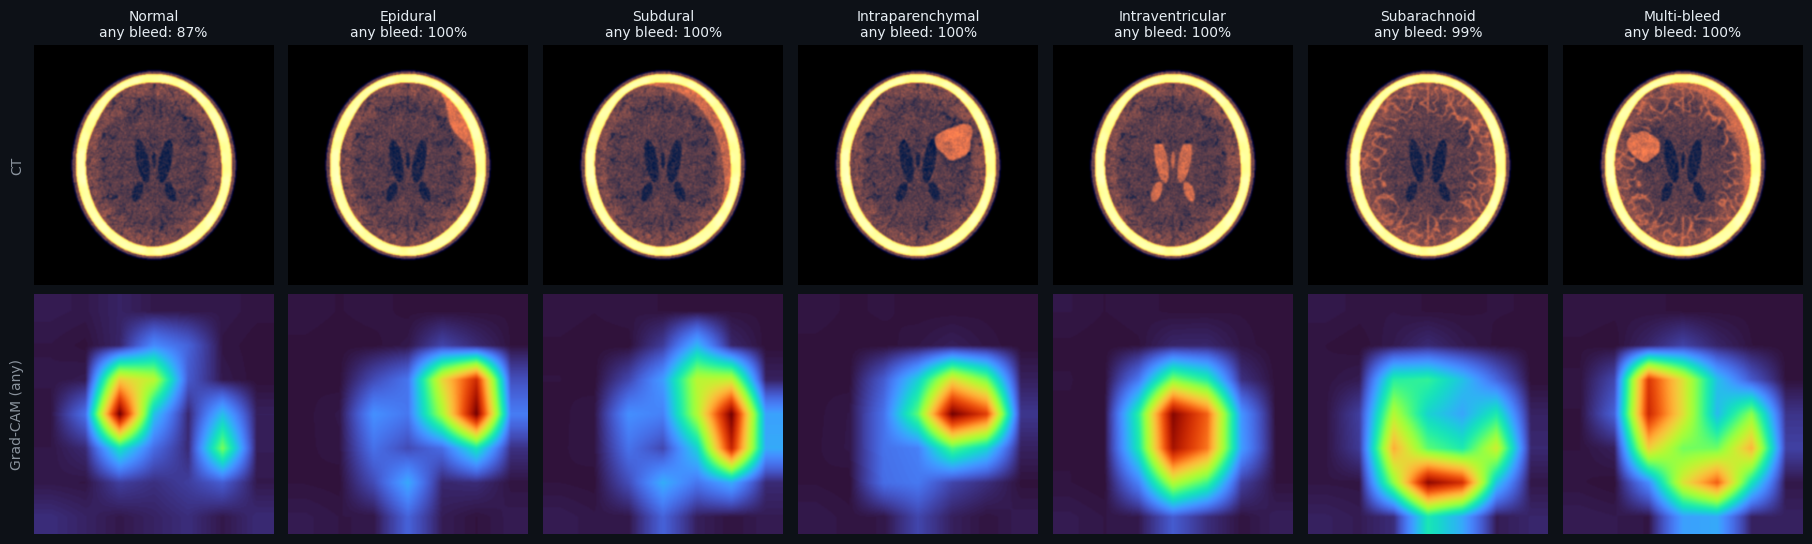

,any,epidural,intraparenchymal,intraventricular,subarachnoid,subdural
Normal,87%,14%,12%,3%,32%,54%
Epidural,100%,61%,12%,1%,19%,59%
Subdural,100%,5%,2%,1%,14%,99%
Intraparenchymal,100%,1%,96%,11%,28%,12%
Intraventricular,100%,4%,44%,98%,32%,16%
Subarachnoid,99%,2%,6%,9%,100%,16%
Multi-bleed,100%,5%,59%,22%,99%,28%


In [22]:
# ---------- Static snapshot: every preset through the trained ensemble ----------
# (This cell also renders in a committed Kaggle notebook, where live widgets are not interactive.)
names, prob_rows = [], []
fig, axes = plt.subplots(2, len(GALLERY), figsize=(2.6 * len(GALLERY), 5.6), facecolor=BG)
for col, (name, ks) in enumerate(GALLERY):
    P = make_phantom(ks, size=0.85, seed=7)
    img = hu_to_model_input(P["hu"])
    probs, cam, _ = infer(img, "Ensemble (A + B)", "any")
    names.append(name); prob_rows.append(probs)
    axes[0, col].imshow(img, interpolation="bicubic")
    axes[0, col].set_title(f"{name}\nany bleed: {probs[0] * 100:.0f}%", color=FG, fontsize=10)
    axes[1, col].imshow(img[..., 0], cmap="gray", vmin=0, vmax=255, interpolation="bicubic")
    axes[1, col].imshow(cam, cmap="turbo", alpha=np.clip(cam * 1.25, 0, 0.75), interpolation="bicubic", vmin=0, vmax=1)
    axes[0, col].axis("off"); axes[1, col].axis("off")
axes[0, 0].text(-0.04, 0.5, "CT", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right", color=MUTED)
axes[1, 0].text(-0.04, 0.5, "Grad-CAM (any)", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right", color=MUTED)
plt.tight_layout()
plt.show()

snapshot = pd.DataFrame(prob_rows, index=names, columns=LABEL_COLS)
try:
    display(snapshot.style.format("{:.0%}").background_gradient(cmap="Reds", axis=None, vmin=0, vmax=1))
except Exception:
    print(snapshot.round(2))

**Things to try**
- Compare the ensemble with Model A and Model B on the same real held-out slice.
- Switch between the brain, subdural, and bone windows.
- Select different Grad-CAM targets and compare the highlighted regions.
- Upload a de-identified DICOM slice and inspect the model output.
- Treat every output as an unvalidated research prediction, never as a diagnosis.

## Part 13: Open the demo as a separate web page (Gradio)

Run this cell **after training and evaluation**. It creates a standalone browser interface with:
- A real held-out test-slice explorer.
- A de-identified single-slice CT DICOM upload option.
- Six model scores, Grad-CAM, and model-specific validation thresholds.

Kaggle must have Internet enabled for Gradio's temporary public share URL. Open the printed `gradio.live` link in a new browser tab. The link is temporary and expires when the Kaggle session stops. Do not share identifiable patient data.

In [40]:
import gradio as gr
import random
from pathlib import Path

# ---------------------------------------------------------------------------
# Backend glue (same logic as before) --------------------------------------
# ---------------------------------------------------------------------------
def _gradio_render(img_u8, model_name, cam_target, source_label):
    probs, cam, target_idx = infer(img_u8, which=model_name, cam_target=cam_target)
    thresholds = DEMO_THRESHOLDS.get(model_name, DEMO_THR)
    html, fig = compose_view(img_u8, probs, cam, target_idx, truth=None, mask=None,
                             view=VIEW_CHOICES[0], outline=False, thr=thresholds)
    header = ("<div class='bb-source'><span class='bb-dot'></span>"
              f"<div><b>{source_label}</b><small>Research and education only. Not a diagnosis.</small></div></div>")
    return header + html, fig

def gradio_test_slice(slice_position, model_name, cam_target):
    if len(test_ids) == 0:
        raise gr.Error("The held-out test split is empty.")
    pos = int(np.clip(round(slice_position), 0, len(test_ids) - 1))
    idx = int(test_ids[pos])
    img_u8 = np.asarray(images[idx]).astype(np.uint8)
    sid = str(data.iloc[idx]["slice"])
    return _gradio_render(img_u8, model_name, cam_target, f"Held-out test slice {pos}: {sid}")

def gradio_dicom(file_obj, model_name, cam_target):
    if file_obj is None:
        raise gr.Error("Upload one de-identified CT DICOM file (.dcm) first.")
    path = file_obj if isinstance(file_obj, str) else getattr(file_obj, "name", None)
    if not path or not Path(path).exists():
        raise gr.Error("Could not read the uploaded file. Try uploading it again.")
    ds = pydicom.dcmread(path, force=True)
    if str(getattr(ds, "Modality", "")).upper() != "CT":
        raise gr.Error("Only CT DICOM files are supported.")
    arr = np.asarray(ds.pixel_array)
    if arr.ndim != 2:
        raise gr.Error(f"Expected one 2D slice, received shape {arr.shape}.")
    hu = dicom_to_hu(ds, pixel_array=arr)
    img_u8 = hu_to_three_channel(hu, photometric=getattr(ds, "PhotometricInterpretation", "MONOCHROME2"))
    return _gradio_render(img_u8, model_name, cam_target, "Uploaded single-slice CT DICOM")

# slice navigation helpers
_N = max(0, len(test_ids) - 1)
def _prev(v): return max(0, int(v) - 1)
def _next(v): return min(_N, int(v) + 1)
def _rand(): return random.randint(0, _N)


# --- BRAIN-START (photo-based, generated) ---
BRAIN_B64 = "..."
CLIP_PTS = "1139,117 1105,102 1071,98 1047,84 1029,82 1001,65 965,62 942,48 919,41 888,41 836,30 788,29 756,33 731,42 656,44 572,74 541,93 490,106 420,159 363,218 332,241 312,278 290,294 266,302 262,320 255,325 238,325 236,349 228,352 225,363 214,363 213,386 234,415 228,455 219,476 202,490 198,528 175,538 166,550 166,558 200,587 210,672 222,682 234,721 244,733 286,754 297,765 310,810 330,846 376,885 441,918 479,928 546,928 594,911 607,902 622,902 623,919 614,967 627,1023 714,1023 739,936 758,914 769,891 787,881 823,880 852,871 872,852 882,825 948,818 979,809 996,797 1008,779 1031,766 1043,744 1102,735 1149,696 1279,696 1324,685 1342,673 1367,645 1380,604 1379,544 1365,476 1362,437 1351,408 1346,353 1304,271 1288,256 1274,229 1248,195 1216,167"
REGIONS = {"frontal": [[900, 45], [1200, 90], [1320, 255], [1372, 450], [1358, 630], [1320, 660], [1185, 682], [1080, 600], [990, 450], [930, 300]], "parietal": [[435, 165], [660, 60], [900, 45], [930, 300], [990, 450], [840, 450], [660, 450], [495, 390]], "occipital": [[225, 450], [285, 255], [435, 165], [495, 390], [458, 495], [420, 645], [300, 705], [225, 600]], "temporal": [[458, 495], [660, 450], [840, 450], [990, 450], [1080, 600], [1185, 682], [1050, 702], [780, 708], [600, 693], [420, 660]], "cerebellum": [[338, 750], [420, 682], [570, 675], [675, 735], [690, 810], [630, 885], [510, 922], [390, 885]], "stem": [[720, 698], [885, 735], [840, 840], [750, 900], [660, 1035], [622, 1035], [675, 885], [705, 780]]}
NODES = [[753, 809], [461, 430], [1190, 302], [1009, 606], [673, 467], [802, 236], [1027, 213], [671, 219], [570, 346], [841, 72], [969, 474], [909, 358], [856, 542], [1215, 533], [267, 612], [1087, 424], [600, 688], [1279, 413], [305, 493], [416, 263], [869, 752], [593, 867], [390, 691], [530, 165], [520, 592], [270, 376], [666, 94], [472, 810], [711, 346], [758, 676]]
EDGES = [[0, 20], [0, 21], [0, 29], [1, 8], [1, 18], [1, 19], [1, 24], [1, 25], [2, 6], [2, 15], [2, 17], [3, 10], [3, 12], [3, 13], [3, 15], [3, 20], [4, 8], [4, 24], [4, 28], [5, 7], [5, 9], [5, 11], [5, 28], [6, 11], [6, 15], [7, 9], [7, 23], [7, 26], [7, 28], [8, 19], [8, 28], [9, 26], [10, 11], [10, 12], [10, 15], [12, 29], [13, 15], [13, 17], [14, 18], [14, 22], [14, 25], [15, 17], [16, 21], [16, 24], [16, 27], [16, 29], [18, 25], [19, 23], [19, 25], [20, 29], [21, 27], [22, 24], [22, 27], [23, 26]]

def _build_brain():
    reg = "".join('<polygon class="region" data-r="%s" points="%s"/>' % (k, " ".join("%d,%d" % tuple(pt) for pt in v))
                  for k, v in REGIONS.items())
    edges = "".join('<line class="edge" data-a="%d" data-b="%d" x1="%d" y1="%d" x2="%d" y2="%d"/>'
                    % (a, b, NODES[a][0], NODES[a][1], NODES[b][0], NODES[b][1]) for a, b in EDGES)
    nodes = "".join('<circle class="node" cx="%d" cy="%d" r="9" style="animation-delay:-%.1fs"/>'
                    % (x, y, (i * 0.37) % 3) for i, (x, y) in enumerate(NODES))
    return (
        '<div class="bb-stage">'
        '<img class="bb-img" alt="Illustration of a human brain with highlighted regions" src="data:image/webp;base64,' + BRAIN_B64 + '">'
        '<svg class="bb-brain" viewBox="0 0 1536 1024" role="img" aria-label="Interactive brain overlay">'
        '<defs><clipPath id="bbc"><polygon points="' + CLIP_PTS + '"/></clipPath>'
        '<linearGradient id="bbb" x1="0" y1="0" x2="0" y2="1"><stop offset="0" stop-color="#5fd0e0" stop-opacity="0"/>'
        '<stop offset=".85" stop-color="#5fd0e0" stop-opacity=".35"/><stop offset="1" stop-color="#bff6ff" stop-opacity=".95"/></linearGradient></defs>'
        '<g clip-path="url(#bbc)">' + reg + '<rect class="beam" x="0" y="0" width="1536" height="90" fill="url(#bbb)"/></g>'
        '<g class="net" clip-path="url(#bbc)">' + edges + nodes + '<g class="sig"></g></g>'
        '<circle class="hot h2" cx="1100" cy="420" r="70"/><circle class="hot h2 h3" cx="1100" cy="420" r="70"/>'
        '</svg></div>')

BRAIN = _build_brain()
# --- BRAIN-END ---

# ---------------------------------------------------------------------------
# Look & feel: a radiology reading room. Slate light-box, bone type, cyan dye,
# coral reserved for findings. Built for wide desktop screens.
# ---------------------------------------------------------------------------
CSS = r"""
@import url('https://fonts.googleapis.com/css2?family=Fraunces:opsz,wght@9..144,400;9..144,600&family=Public+Sans:wght@400;500;600&display=swap');
:root{--bg:#0f161c;--panel:#1b262f;--line:#2a3945;--text:#e3e9ee;--mute:#8fa1ae;--cyan:#5fd0e0;--coral:#ff7a66}
html{scroll-behavior:smooth} html,body{background:var(--bg) !important}
footer{display:none !important}
body::before{content:"";position:fixed;inset:0;z-index:0;pointer-events:none;
  background:radial-gradient(1100px 700px at 78% 0%,rgba(95,208,224,.12),transparent 60%),
             radial-gradient(900px 600px at 0% 100%,rgba(255,122,102,.07),transparent 60%)}
#bb-neurons{position:fixed;inset:0;width:100vw;height:100vh;z-index:0;pointer-events:none;opacity:1}
#bb-spot{position:fixed;width:560px;height:560px;margin:-280px 0 0 -280px;border-radius:50%;z-index:0;pointer-events:none;
  background:radial-gradient(circle,rgba(95,208,224,.09),transparent 65%)}
#bb-progress{position:fixed;top:0;left:0;height:3px;width:0;z-index:200;background:linear-gradient(90deg,#5fd0e0,#ff7a66)}
#bb-toast{position:fixed;right:32px;bottom:32px;z-index:200;display:flex;gap:10px;align-items:center;padding:12px 18px;
  background:rgba(27,38,47,.92);border:1px solid var(--cyan);border-radius:14px;color:var(--text);backdrop-filter:blur(10px);
  transform:translateY(30px);opacity:0;transition:.35s cubic-bezier(.2,.9,.3,1.2);pointer-events:none}
#bb-toast.show{transform:none;opacity:1}
#bb-toast i{width:9px;height:9px;border-radius:50%;background:var(--cyan);box-shadow:0 0 12px var(--cyan)}

.gradio-container{max-width:none !important;width:100% !important;margin:0 !important;background:transparent !important;
  padding:0 clamp(18px,4.5vw,110px) 40px !important;position:relative;z-index:1;
  font-family:'Public Sans',system-ui,sans-serif !important;color:var(--text)}


/* nav */
.bb-nav{position:sticky;top:12px;z-index:60;display:flex;justify-content:space-between;align-items:center;margin-top:14px;
  padding:10px 12px 10px 20px;border:1px solid var(--line);border-radius:999px;background:rgba(15,22,28,.72);backdrop-filter:blur(14px)}
.bb-brand{display:flex;gap:10px;align-items:center;font-family:'Fraunces',serif;font-size:1.15rem;font-weight:600}
.bb-brand svg{width:26px;height:26px}
.bb-nav nav{display:flex;gap:6px}
.bb-nav a{color:var(--mute);text-decoration:none;padding:8px 16px;border-radius:999px;font-size:.92rem;font-weight:500;cursor:pointer;transition:.2s}
.bb-nav a:hover{color:var(--text);background:rgba(95,208,224,.12)}
.bb-nav a.cta{background:var(--cyan);color:#06222a;font-weight:600}

/* hero fills the desktop viewport */
.bb-hero{display:grid;grid-template-columns:.9fr 1.1fr;gap:clamp(24px,4vw,80px);align-items:center;min-height:calc(100vh - 120px);padding:24px 0 56px;position:relative}
.bb-hero h1{font-family:'Fraunces',serif;font-weight:600;font-size:clamp(3rem,6.4vw,6.4rem);line-height:.98;letter-spacing:-.03em;margin:0 0 18px;
  background:linear-gradient(100deg,#e3e9ee 25%,#5fd0e0 95%);-webkit-background-clip:text;background-clip:text;color:transparent}
.bb-type{font-family:'Fraunces',serif;font-size:clamp(1.2rem,1.9vw,1.8rem);color:var(--cyan);min-height:2.2em;margin:0 0 12px}
.bb-type::after{content:"";display:inline-block;width:2px;height:1.1em;background:var(--cyan);margin-left:4px;vertical-align:-.15em;animation:caret 1s steps(1) infinite}
@keyframes caret{50%{opacity:0}}
.bb-hero p{color:var(--mute);font-size:clamp(1rem,1.2vw,1.2rem);line-height:1.65;max-width:56ch;margin:0 0 24px}
.bb-cta{display:flex;gap:12px;flex-wrap:wrap;margin-bottom:22px}
.bb-cta a{padding:14px 26px;border-radius:999px;font-weight:600;text-decoration:none;cursor:pointer;transition:transform .15s,box-shadow .25s;position:relative;overflow:hidden}
.bb-cta .p{background:linear-gradient(135deg,#5fd0e0,#2aa5c0);color:#04212a;box-shadow:0 8px 28px rgba(95,208,224,.3)}
.bb-cta .s{border:1px solid rgba(95,208,224,.5);color:#bfeaf1;background:rgba(95,208,224,.07)}
.bb-cta a:hover{box-shadow:0 12px 34px rgba(95,208,224,.4)}
.bb-chips{display:flex;flex-wrap:wrap;gap:8px}
.bb-chip{border:1px solid var(--line);background:rgba(27,38,47,.7);padding:7px 14px;border-radius:999px;font-size:.86rem;transition:.2s}
.bb-chip:hover{border-color:var(--cyan);transform:translateY(-2px)}
.bb-stats{display:flex;gap:34px;margin-top:30px}
.bb-stats div{border-left:2px solid var(--cyan);padding-left:14px}
.bb-stats b{display:block;font-family:'Fraunces',serif;font-size:2.2rem}
.bb-stats span{color:var(--mute);font-size:.85rem}
.bb-scroll{position:absolute;left:50%;bottom:6px;width:24px;height:38px;border:2px solid var(--mute);border-radius:14px;opacity:.7}
.bb-scroll::after{content:"";position:absolute;left:50%;top:7px;width:4px;height:7px;margin-left:-2px;border-radius:2px;background:var(--cyan);animation:wheel 1.8s infinite}
@keyframes wheel{0%{opacity:0;transform:translateY(0)}30%{opacity:1}100%{opacity:0;transform:translateY(14px)}}

/* brain (photo + live overlay) */
.bb-brainwrap{position:relative;display:flex;flex-direction:column;align-items:center}
.bb-brainwrap::before{content:"";position:absolute;top:6%;width:96%;aspect-ratio:1.3;border-radius:50%;
  background:radial-gradient(circle,rgba(95,208,224,.26),transparent 66%);filter:blur(26px);animation:breathe 6s ease-in-out infinite}
@keyframes breathe{50%{transform:scale(1.08);opacity:.65}}
.bb-tilt{perspective:1200px;width:100%;max-width:900px}
.bb-tiltin{transition:transform .18s ease-out;transform-style:preserve-3d}
.bb-stage{position:relative;animation:float 7s ease-in-out infinite;filter:drop-shadow(0 30px 60px rgba(0,0,0,.55))}
@keyframes float{50%{transform:translateY(-12px)}}
.bb-img{display:block;width:100%;height:auto;user-select:none;-webkit-user-drag:none}
.bb-brain{position:absolute;inset:0;width:100%;height:100%;overflow:visible}
.bb-brain .region{fill:transparent;cursor:pointer;transition:fill .25s,stroke .25s;stroke:transparent;stroke-width:3}
.bb-brain .region:hover,.bb-brain .region.on{fill:rgba(95,208,224,.2);stroke:rgba(190,246,255,.85)}
.bb-brain .edge{stroke:#bff6ff;stroke-opacity:.38;stroke-width:2.4;pointer-events:none}
.bb-brain .node{fill:#d9fbff;pointer-events:none;animation:fire 3.4s ease-in-out infinite;transform-box:fill-box;transform-origin:center;filter:drop-shadow(0 0 8px #5fd0e0)}
@keyframes fire{0%,100%{opacity:.4;transform:scale(.7)}50%{opacity:1;transform:scale(1.4)}}
.bb-brain .node.zap{animation:none;fill:#fff;opacity:1;transform:scale(2.6)}
.bb-brain .spark{fill:#fff;filter:drop-shadow(0 0 10px #5fd0e0);pointer-events:none}
.bb-brain .beam{animation:slice 6s ease-in-out infinite;pointer-events:none}
@keyframes slice{0%,100%{transform:translateY(0)}50%{transform:translateY(940px)}}
.bb-brain .hot{fill:none;stroke:#ff7a66;stroke-width:5;pointer-events:none;transform-box:fill-box;transform-origin:center;animation:ring 2.8s ease-out infinite}
.bb-brain .hot.h3{animation-delay:1.4s}
@keyframes ring{0%{opacity:.95;transform:scale(.5)}100%{opacity:0;transform:scale(1.9)}}
.bb-region-card{margin-top:4px;width:100%;max-width:600px;min-height:84px;background:rgba(27,38,47,.85);backdrop-filter:blur(8px);
  border:1px solid var(--line);border-radius:14px;padding:14px 18px;transition:border-color .25s,transform .25s}
.bb-region-card.live{border-color:var(--cyan);transform:translateY(-2px)}
.bb-region-card b{font-family:'Fraunces',serif;font-size:1.1rem;color:var(--cyan)}
.bb-region-card span{display:block;color:var(--mute);font-size:.92rem;line-height:1.5;margin-top:4px}

/* how-it-works */
.bb-how{display:grid;grid-template-columns:repeat(3,1fr);gap:18px;margin:10px 0 28px}
.bb-how div{background:rgba(27,38,47,.72);border:1px solid var(--line);border-radius:16px;padding:20px 22px;backdrop-filter:blur(8px);transition:.25s}
.bb-how div:hover{border-color:var(--cyan);transform:translateY(-4px)}
.bb-how b{display:block;margin-bottom:6px;color:var(--cyan);font-family:'Fraunces',serif;font-size:1.2rem}
.bb-how span{color:var(--mute);line-height:1.55}
.bb-reveal{opacity:0;transform:translateY(22px);transition:opacity .6s ease,transform .6s ease,border-color .25s}
.bb-reveal.in{opacity:1;transform:none}

.bb-notice{display:flex;gap:12px;margin:8px 0 26px;padding:14px 18px;border-left:3px solid var(--coral);background:rgba(255,122,102,.08);border-radius:8px;line-height:1.5}
.bb-notice b{color:var(--coral)}

/* workspace */
#bb-lab{gap:24px !important;align-items:flex-start !important;scroll-margin-top:90px}
.bb-side{position:sticky;top:84px;background:rgba(27,38,47,.72) !important;border:1px solid var(--line) !important;border-radius:18px !important;padding:18px !important}
.bb-main{min-height:70vh}
.gradio-container label span,.gradio-container .block-label,.gradio-container .info{color:var(--mute) !important}
.gradio-container input,.gradio-container .wrap{border-radius:12px !important}
.gradio-container input[type=range]{accent-color:#5fd0e0}
button[role=tab]{font-weight:600 !important;color:var(--mute) !important;transition:.2s}
button[role=tab][aria-selected=true]{color:var(--cyan) !important;border-color:var(--cyan) !important}

/* buttons */
.gradio-container button{position:relative;overflow:hidden}
button.primary{background:linear-gradient(135deg,#5fd0e0,#2aa5c0 60%,#4fb6d6) !important;color:#04212a !important;border:0 !important;border-radius:999px !important;
  font-weight:600 !important;letter-spacing:.01em;padding:14px 22px !important;box-shadow:0 8px 26px rgba(95,208,224,.28),inset 0 1px 0 rgba(255,255,255,.4);
  transition:transform .18s,box-shadow .25s}
button.primary::after{content:"";position:absolute;top:0;left:-70%;width:45%;height:100%;transform:skewX(-20deg);
  background:linear-gradient(90deg,transparent,rgba(255,255,255,.55),transparent);transition:left .6s}
button.primary:hover{transform:translateY(-3px);box-shadow:0 14px 36px rgba(95,208,224,.45)}
button.primary:hover::after{left:130%}
button.primary:active{transform:translateY(0) scale(.98)}
button.secondary{background:rgba(95,208,224,.08) !important;border:1px solid rgba(95,208,224,.45) !important;color:#bfeaf1 !important;border-radius:999px !important;
  font-weight:600 !important;transition:.2s}
button.secondary:hover{background:rgba(95,208,224,.18) !important;transform:translateY(-2px);box-shadow:0 8px 22px rgba(95,208,224,.18)}
.bb-ic button::before{content:"";display:inline-block;width:1.05em;height:1.05em;margin-right:8px;vertical-align:-.15em;background:currentColor;
  -webkit-mask:var(--ic) center/contain no-repeat;mask:var(--ic) center/contain no-repeat}
#bb-go,#bb-go2{--ic:url("data:image/svg+xml,%3Csvg xmlns='http://www.w3.org/2000/svg' viewBox='0 0 24 24'%3E%3Cpath d='M7 4l13 8-13 8z'/%3E%3C/svg%3E")}
#bb-prev{--ic:url("data:image/svg+xml,%3Csvg xmlns='http://www.w3.org/2000/svg' viewBox='0 0 24 24'%3E%3Cpath d='M15 5l-7 7 7 7' fill='none' stroke='black' stroke-width='3'/%3E%3C/svg%3E")}
#bb-next{--ic:url("data:image/svg+xml,%3Csvg xmlns='http://www.w3.org/2000/svg' viewBox='0 0 24 24'%3E%3Cpath d='M9 5l7 7-7 7' fill='none' stroke='black' stroke-width='3'/%3E%3C/svg%3E")}
#bb-rand{--ic:url("data:image/svg+xml,%3Csvg xmlns='http://www.w3.org/2000/svg' viewBox='0 0 24 24'%3E%3Cpath d='M12 2l2.6 7.4L22 12l-7.4 2.6L12 22l-2.6-7.4L2 12l7.4-2.6z'/%3E%3C/svg%3E")}
.bb-rip{position:absolute;border-radius:50%;background:rgba(255,255,255,.55);transform:scale(0);animation:rip .6s ease-out;pointer-events:none}
@keyframes rip{to{transform:scale(4);opacity:0}}
button:focus-visible,input:focus-visible,a:focus-visible{outline:2px solid var(--cyan) !important;outline-offset:3px}

/* results */
.bb-source{display:flex;gap:12px;align-items:center;padding:14px 18px;border-radius:14px;background:rgba(27,38,47,.8);border:1px solid var(--line);margin-bottom:12px}
.bb-source small{display:block;color:#f0b429;margin-top:2px}
.bb-dot{width:10px;height:10px;border-radius:50%;background:var(--cyan);animation:pulse 2s infinite}
@keyframes pulse{0%{box-shadow:0 0 0 0 rgba(95,208,224,.7)}70%,100%{box-shadow:0 0 0 12px rgba(95,208,224,0)}}
#bb-results>*{animation:rin .5s ease both}
@keyframes rin{from{opacity:0;transform:translateY(10px)}to{opacity:1;transform:none}}
.bb-empty{display:flex;flex-direction:column;align-items:center;text-align:center;gap:10px;padding:60px 20px;border:1px dashed var(--line);border-radius:18px;color:var(--mute)}
.bb-empty b{font-family:'Fraunces',serif;font-size:1.4rem;color:var(--text)}
.bb-rings{position:relative;width:110px;height:110px;margin-bottom:6px}
.bb-rings i{position:absolute;inset:0;border:2px solid var(--cyan);border-radius:50%;opacity:0;animation:ping 3s ease-out infinite}
.bb-rings i:nth-child(2){animation-delay:1s}.bb-rings i:nth-child(3){animation-delay:2s}
@keyframes ping{0%{transform:scale(.2);opacity:.8}100%{transform:scale(1);opacity:0}}
.bb-foot{text-align:center;color:var(--mute);font-size:.85rem;padding:26px 0 6px}

@media (min-width:1900px){.bb-hero h1{font-size:7rem}}
@media (max-width:980px){.bb-hero{grid-template-columns:1fr;min-height:0}.bb-how{grid-template-columns:1fr}.bb-side{position:static}.bb-nav nav a:not(.cta){display:none}}
@media (prefers-reduced-motion:reduce){*{animation:none !important;transition:none !important}.bb-reveal{opacity:1;transform:none}}
"""

HERO = r"""
<header class="bb-nav">
  <div class="bb-brand"><svg viewBox="0 0 32 32"><circle cx="16" cy="16" r="14" fill="none" stroke="#5fd0e0" stroke-width="2"/><path d="M8 17c3-6 5 4 8-2s5 3 8-1" fill="none" stroke="#5fd0e0" stroke-width="2" stroke-linecap="round"/></svg>Brain Bleed Lab</div>
  <nav><a data-go="bb-top">Home</a><a data-go="bb-how">How it works</a><a class="cta" data-go="bb-lab">Open the lab</a></nav>
</header>
<section class="bb-hero" id="bb-top">
  <div>
    <h1>Brain Bleed Detection</h1>
    <div class="bb-type" id="bb-type" data-lines='["Read a head CT like a model does.","See exactly where it looked.","Compare two models and their ensemble.","Built to teach, not to diagnose."]'></div>
    <p>Step through held-out RSNA slices or drop in one de-identified DICOM. Each result shows the predicted
       hemorrhage types and a Grad-CAM heatmap of the regions that drove them.</p>
    <div class="bb-cta"><a class="p bb-mag" data-go="bb-lab">Open the lab</a><a class="s bb-mag" data-go="bb-how">How it works</a></div>
    <div class="bb-chips"><span class="bb-chip">RSNA hemorrhage data</span><span class="bb-chip">Ensemble of two models</span><span class="bb-chip">Grad-CAM heatmaps</span><span class="bb-chip">DICOM upload</span></div>
    <div class="bb-stats">
      <div><b class="bb-count" data-to="5">0</b><span>hemorrhage types</span></div>
      <div><b class="bb-count" data-to="3">0</b><span>model options</span></div>
      <div><b class="bb-count" data-to="1">0</b><span>click to analyze</span></div>
    </div>
  </div>
  <div class="bb-brainwrap">
    <div class="bb-tilt"><div class="bb-tiltin">__BRAIN__</div></div>
    <div class="bb-region-card" id="bb-region-card"><b>Hover or tap the brain</b><span>Pick a lobe to see which bleed types tend to appear there. Click the brain to fire a signal cascade.</span></div>
  </div>
  <div class="bb-scroll" aria-hidden="true"></div>
</section>
<div class="bb-notice" role="note"><span><b>Research and education prototype.</b> Not a medical device. Never use it for diagnosis or clinical decisions.</span></div>
""".replace("__BRAIN__", BRAIN)

HOW = """
<div class="bb-how" id="bb-how">
  <div class="bb-reveal"><b>1. Pick a model</b><span>Use model A, model B, or the ensemble that averages both.</span></div>
  <div class="bb-reveal" style="transition-delay:.12s"><b>2. Choose a slice</b><span>Browse the held-out test split, jump to a random one, or upload a CT slice.</span></div>
  <div class="bb-reveal" style="transition-delay:.24s"><b>3. Read the heatmap</b><span>Grad-CAM highlights the regions that pushed the prediction.</span></div>
</div>
"""

EMPTY = """<div class="bb-empty"><div class="bb-rings"><i></i><i></i><i></i></div>
<b>No analysis yet</b><span>Choose a slice or upload a DICOM, then press Analyze.<br>Predictions and the Grad-CAM heatmap will appear here.</span></div>"""

FOOT = "<div class='bb-foot'>Built for learning. Keep your Kaggle session running while the demo link is in use.</div>"

HEAD = r"""
<script>
(function(){
const DPR=devicePixelRatio||1, reduce=matchMedia('(prefers-reduced-motion: reduce)').matches;
const INFO={frontal:["Frontal lobe","Planning and movement. Subdural and intraparenchymal bleeds often appear here after head injury."],
 parietal:["Parietal lobe","Touch and spatial sense. Subarachnoid blood can track along the surface folds here."],
 temporal:["Temporal lobe","Memory and hearing. A common site for contusions and epidural bleeds after side impacts."],
 occipital:["Occipital lobe","Vision. Bleeds here may cause visual field loss."],
 cerebellum:["Cerebellum","Balance and coordination. Bleeds here can press on the brainstem."],
 stem:["Brainstem","Breathing and alertness. Bleeding near here is time-critical."]};
const el=(t,id)=>{const e=document.createElement(t);if(id)e.id=id;document.documentElement.appendChild(e);return e;};

// ---- neuron network (whole site) ----
const cv=el('canvas','bb-neurons'),ctx=cv.getContext('2d');let W,H,pts=[],pulses=[],mouse={x:-999,y:-999};
function size(){W=cv.width=innerWidth*DPR;H=cv.height=innerHeight*DPR;
 const n=Math.min(170,Math.floor(innerWidth*innerHeight/10500));
 pts=Array.from({length:n},()=>({x:Math.random()*W,y:Math.random()*H,vx:(Math.random()-.5)*.35*DPR,vy:(Math.random()-.5)*.35*DPR,r:(1.3+Math.random()*2.1)*DPR}));}
addEventListener('resize',size);size();
window.bbBurst=(x,y)=>pulses.push({x:x*DPR,y:y*DPR,r:0});
const D=160*DPR;
(function frame(){
 ctx.clearRect(0,0,W,H);
 for(const p of pts){if(!reduce){p.x+=p.vx;p.y+=p.vy;}if(p.x<0||p.x>W)p.vx*=-1;if(p.y<0||p.y>H)p.vy*=-1;}
 for(let i=0;i<pts.length;i++){const a=pts[i];
  for(let j=i+1;j<pts.length;j++){const b=pts[j],d=Math.hypot(a.x-b.x,a.y-b.y);
   if(d<D){ctx.strokeStyle='rgba(95,208,224,'+(.38*(1-d/D))+')';ctx.lineWidth=DPR*.8;ctx.beginPath();ctx.moveTo(a.x,a.y);ctx.lineTo(b.x,b.y);ctx.stroke();}}
  const md=Math.hypot(a.x-mouse.x,a.y-mouse.y);
  if(md<D*1.5){ctx.strokeStyle='rgba(155,231,242,'+(.55*(1-md/(D*1.5)))+')';ctx.beginPath();ctx.moveTo(a.x,a.y);ctx.lineTo(mouse.x,mouse.y);ctx.stroke();
   if(!reduce){a.x+=(mouse.x-a.x)*.002;a.y+=(mouse.y-a.y)*.002;}}
  let g=0;for(const u of pulses){const dd=Math.abs(Math.hypot(a.x-u.x,a.y-u.y)-u.r);if(dd<30*DPR)g=Math.max(g,1-dd/(30*DPR));}
  ctx.fillStyle=g>0?'rgba(255,122,102,'+(.4+g*.6)+')':'rgba(140,225,240,.85)';
  ctx.beginPath();ctx.arc(a.x,a.y,a.r*(1+g*1.8),0,6.283);ctx.fill();}
 for(const u of pulses){u.r+=8*DPR;ctx.strokeStyle='rgba(255,122,102,'+Math.max(0,.45-u.r/(1000*DPR))+')';ctx.beginPath();ctx.arc(u.x,u.y,u.r,0,6.283);ctx.stroke();}
 pulses=pulses.filter(u=>u.r<1000*DPR);requestAnimationFrame(frame);})();

// ---- cursor spotlight, scroll progress, tilt ----
const spot=el('div','bb-spot'),prog=el('div','bb-progress'),toastEl=el('div','bb-toast');
addEventListener('mousemove',e=>{mouse.x=e.clientX*DPR;mouse.y=e.clientY*DPR;spot.style.left=e.clientX+'px';spot.style.top=e.clientY+'px';
 const t=document.querySelector('.bb-tiltin');if(t&&!reduce){const x=e.clientX/innerWidth-.5,y=e.clientY/innerHeight-.5;t.style.transform='rotateY('+x*18+'deg) rotateX('+(-y*12)+'deg)';}});
addEventListener('click',e=>window.bbBurst(e.clientX,e.clientY));
addEventListener('scroll',()=>{const h=document.documentElement;prog.style.width=(scrollY/(h.scrollHeight-innerHeight||1)*100)+'%';},{passive:true});
function toast(msg){toastEl.innerHTML='<i></i>'+msg;toastEl.classList.add('show');clearTimeout(toast.t);toast.t=setTimeout(()=>toastEl.classList.remove('show'),2600);}

// ---- ripple on buttons ----
document.addEventListener('pointerdown',e=>{const b=e.target.closest('button.primary,button.secondary,.bb-cta a');if(!b)return;
 const r=b.getBoundingClientRect(),s=Math.max(r.width,r.height),d=document.createElement('span');d.className='bb-rip';
 d.style.cssText='width:'+s+'px;height:'+s+'px;left:'+(e.clientX-r.left-s/2)+'px;top:'+(e.clientY-r.top-s/2)+'px';b.appendChild(d);setTimeout(()=>d.remove(),650);});
// magnetic hero buttons
document.addEventListener('mousemove',e=>{document.querySelectorAll('.bb-mag').forEach(m=>{const r=m.getBoundingClientRect(),dx=e.clientX-(r.left+r.width/2),dy=e.clientY-(r.top+r.height/2);
 m.style.transform=Math.hypot(dx,dy)<110?'translate('+dx*.18+'px,'+dy*.25+'px)':'';});});
// smooth nav
document.addEventListener('click',e=>{const a=e.target.closest('[data-go]');if(a){const t=document.getElementById(a.dataset.go);if(t)t.scrollIntoView({behavior:'smooth',block:'start'});}});

// ---- typewriter ----
function typer(){const t=document.getElementById('bb-type');if(!t||t.dataset.ok)return;t.dataset.ok=1;const L=JSON.parse(t.dataset.lines);let i=0,c=0,del=false;
 (function tick(){const s=L[i];t.textContent=s.slice(0,c);if(!del&&c<s.length){c++;setTimeout(tick,45);}else if(!del){del=true;setTimeout(tick,1600);}
  else if(c>0){c--;setTimeout(tick,22);}else{del=false;i=(i+1)%L.length;setTimeout(tick,300);}})();}

// ---- count-up + reveal ----
function observe(){document.querySelectorAll('.bb-count:not([data-ok]),.bb-reveal:not([data-ok])').forEach(n=>{n.dataset.ok=1;
 new IntersectionObserver((en,o)=>{if(!en[0].isIntersecting)return;o.disconnect();
  if(n.classList.contains('bb-reveal')){n.classList.add('in');return;}
  const to=+n.dataset.to,t0=performance.now();(function s(t){const k=Math.min(1,(t-t0)/1100);n.textContent=Math.round(to*(1-Math.pow(1-k,3)));if(k<1)requestAnimationFrame(s);})(t0);
 },{threshold:.4}).observe(n);});}

// ---- brain: hover info + signals travelling along the network ----
function brain(){const svg=document.querySelector('.bb-brain');if(!svg||svg.dataset.ok)return;svg.dataset.ok=1;
 const card=document.getElementById('bb-region-card');
 svg.querySelectorAll('.region').forEach(r=>{const on=()=>{const i=INFO[r.dataset.r];card.innerHTML='<b>'+i[0]+'</b><span>'+i[1]+'</span>';card.classList.add('live');r.classList.add('on');};
  r.addEventListener('mouseenter',on);r.addEventListener('mouseleave',()=>{r.classList.remove('on');card.classList.remove('live');});});
 const nodes=[...svg.querySelectorAll('.node')],edges=[...svg.querySelectorAll('.edge')],adj=nodes.map(()=>[]);
 edges.forEach(e=>{const a=+e.dataset.a,b=+e.dataset.b;adj[a].push(b);adj[b].push(a);});
 const g=svg.querySelector('.sig'),NS='http://www.w3.org/2000/svg';
 function send(from,hops){if(!adj[from].length||hops<=0)return;const to=adj[from][Math.floor(Math.random()*adj[from].length)],A=nodes[from],B=nodes[to];
  const ax=+A.getAttribute('cx'),ay=+A.getAttribute('cy'),bx=+B.getAttribute('cx'),by=+B.getAttribute('cy');
  const c=document.createElementNS(NS,'circle');c.setAttribute('r',3.4);c.setAttribute('class','spark');g.appendChild(c);const t0=performance.now();
  (function s(t){const k=Math.min(1,(t-t0)/650);c.setAttribute('cx',ax+(bx-ax)*k);c.setAttribute('cy',ay+(by-ay)*k);
   if(k<1)requestAnimationFrame(s);else{c.remove();B.classList.add('zap');setTimeout(()=>B.classList.remove('zap'),420);if(Math.random()<.85)send(to,hops-1);}})(t0);}
 setInterval(()=>{if(!document.hidden)send(Math.floor(Math.random()*nodes.length),5);},800);
 svg.addEventListener('click',()=>{for(let i=0;i<8;i++)setTimeout(()=>send(Math.floor(Math.random()*nodes.length),6),i*110);});}

// ---- announce new results ----
function results(){const r=document.getElementById('bb-results');if(!r||r.dataset.ok)return;r.dataset.ok=1;
 new MutationObserver(()=>{if(!r.querySelector('.bb-source')||r.dataset.seen===r.innerText.slice(0,160))return;r.dataset.seen=r.innerText.slice(0,160);
  toast('Analysis ready');const b=r.getBoundingClientRect();window.bbBurst(b.left+b.width/2,Math.max(120,b.top+90));}).observe(r,{childList:true,subtree:true});}

setInterval(()=>{typer();observe();brain();results();},600);
})();
</script>
"""

theme = gr.themes.Base(primary_hue="cyan", secondary_hue="slate", neutral_hue="slate",
    radius_size=gr.themes.sizes.radius_lg,
    font=[gr.themes.GoogleFont("Public Sans"), "system-ui", "sans-serif"],
).set(body_background_fill="#0f161c", body_text_color="#e3e9ee", block_background_fill="#1b262f",
      block_border_color="#2a3945", input_background_fill="#141c23", input_border_color="#2a3945",
      block_label_text_color="#8fa1ae", button_primary_background_fill="#5fd0e0", button_primary_text_color="#06222a")

# ---------------------------------------------------------------------------
# App -----------------------------------------------------------------------
# ---------------------------------------------------------------------------
with gr.Blocks(theme=theme, css=CSS, head=HEAD, title="Brain Bleed Lab") as brain_bleed_app:
    gr.HTML(HERO)
    gr.HTML(HOW)

    with gr.Row(elem_id="bb-lab", equal_height=False):
        with gr.Column(scale=4, min_width=340, elem_classes="bb-side"):
            model_choice = gr.Dropdown(list(MODEL_CHOICES.keys()), value="Ensemble (A + B)", label="Model",
                                       info="Ensemble averages both models.")
            cam_choice = gr.Dropdown(["any"] + LABEL_COLS[1:], value="any", label="Grad-CAM target",
                                     info="Choose a hemorrhage type or any.")
            with gr.Tabs():
                with gr.Tab("Test slice"):
                    slice_slider = gr.Slider(0, _N, value=0, step=1, label="Held-out test slice index")
                    with gr.Row():
                        prev_btn = gr.Button("Prev", elem_id="bb-prev", elem_classes="bb-ic", variant="secondary")
                        rand_btn = gr.Button("Random", elem_id="bb-rand", elem_classes="bb-ic", variant="secondary")
                        next_btn = gr.Button("Next", elem_id="bb-next", elem_classes="bb-ic", variant="secondary")
                    test_button = gr.Button("Analyze slice", elem_id="bb-go", elem_classes="bb-ic", variant="primary", size="lg")
                with gr.Tab("Upload DICOM"):
                    dicom_input = gr.File(label="Drop one de-identified CT DICOM (.dcm)", file_types=[".dcm"], type="filepath")
                    dicom_button = gr.Button("Analyze DICOM", elem_id="bb-go2", elem_classes="bb-ic", variant="primary", size="lg")
                    clear_btn = gr.Button("Clear", variant="secondary")

        with gr.Column(scale=8, min_width=480, elem_classes="bb-main"):
            out_html = gr.HTML(EMPTY, elem_id="bb-results")
            out_plot = gr.Plot(label="Heatmap view")

    args_t = [slice_slider, model_choice, cam_choice]
    outs = [out_html, out_plot]
    test_button.click(gradio_test_slice, args_t, outs, show_progress="full")
    prev_btn.click(_prev, slice_slider, slice_slider).then(gradio_test_slice, args_t, outs)
    next_btn.click(_next, slice_slider, slice_slider).then(gradio_test_slice, args_t, outs)
    rand_btn.click(_rand, None, slice_slider).then(gradio_test_slice, args_t, outs)
    dicom_button.click(gradio_dicom, [dicom_input, model_choice, cam_choice], outs, show_progress="full")
    clear_btn.click(lambda: (None, EMPTY, None), None, [dicom_input, out_html, out_plot])

    gr.HTML(FOOT)

print("Launching a separate browser demo. Keep this Kaggle session running.")
brain_bleed_app.queue().launch(share=True, inline=False, show_error=True)

Launching a separate browser demo. Keep this Kaggle session running.
* Running on local URL:  http://127.0.0.1:7867
* Running on public URL: https://dfbb5f5e05afa5caa8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Part 14: External validation on the CT-ICH dataset (PhysioNet, 82 patients)

**Why this part exists.** Part 11 lists "no external validation" as a limitation. The archive `computed-tomography-images-for-intracranial-hemorrhage-detection-and-segmentation` is a *different* dataset (Al Hilla Teaching Hospital, Iraq; Siemens scanner; 82 head CTs, about 30 slices each, 5 mm thick; mean age about 28 years). It is not a solution to the RSNA task. What it offers that the RSNA subset in this notebook does not:

| Item | RSNA subset (Parts 2-9) | CT-ICH archive |
|---|---|---|
| Slices per patient | randomly sampled, incomplete | **all slices of every scan** |
| Class prevalence | deliberately enriched | **natural** (PPV/NPV are measured directly, not estimated) |
| Lesion masks | none | **radiologist masks** (`*_HGE_Seg.jpg`), used in Part 15 |
| Source | many sites (competition) | one hospital, one country (a real domain-shift test) |
| Extra label | none | skull fracture per slice (not used here) |

**Rules of this experiment (read before running):**
1. **No retraining and no tuning.** Models A/B and all decision thresholds are the ones fixed on the RSNA *validation* split in Part 9.1. Nothing is selected using CT-ICH results.
2. **The CT-ICH images are 8-bit JPG renderings, not DICOM/HU.** The RSNA input uses three CT windows (brain 40/80, subdural 80/200, bone 600/2800) computed from Hounsfield units. That cannot be reproduced from JPGs. We approximate the input in two ways and report both as a **sensitivity analysis**: `brain_brain_bone` (brain JPG in channels 1-2, bone JPG in channel 3; declared as the primary mode *before* running) and `brain_x3` (brain JPG in all three channels). Any drop in performance mixes real domain shift with this preprocessing mismatch; the two cannot be separated with this data.
3. **Few patients per subtype.** The archive has only a handful of patients for some subtypes (the code prints the exact counts). Slice-level AUCs for those subtypes are very uncertain even if the slice count looks large, because slices of the same patient are highly correlated. Confidence intervals below resample **patients**, not slices.
4. **Licence:** CC BY 4.0. Cite the dataset (PhysioNet page / authors listed in its `README.txt`) in any report. Do not claim clinical validity from 82 scans.

**Requirements:** run Parts 1-9 (so `model_A`, `model_B`, `DEMO_THRESHOLDS`, `operating_table`, `auc_table`, `tt`, `pt_ens` exist) and cell 12.2 (which defines `infer`). Part 13 (Gradio) is not needed.

**14.1 Locate the archive**

The cell looks for the extracted folder or `archive.zip` in the working directory, `DATA_ROOT`, `/content`, Google Drive (`/content/drive/MyDrive`) and Kaggle inputs. Set `CTICH_PATH` manually if it is somewhere else. The archive is about 107 MB and is extracted once to `OUT_DIR/ct_ich`.

In [25]:
# ---------- 14.1 Locate (and extract if needed) the CT-ICH archive ----------
CTICH_FOLDER_NAME = "computed-tomography-images-for-intracranial-hemorrhage-detection-and-segmentation-1.0.0"
CTICH_PATH = None  # optional manual override: the extracted folder OR the path of archive.zip
CTICH_EXTRACT_DIR = OUT_DIR / "ct_ich"

def _is_ct_ich_zip(path):
    try:
        with zipfile.ZipFile(path) as zf:
            return any(n.endswith("hemorrhage_diagnosis.csv") for n in zf.namelist())
    except Exception:
        return False

def _resolve_ct_ich(p):
    """Return the dataset folder for a candidate path, or None."""
    p = Path(p)
    if p.is_dir() and (p / "hemorrhage_diagnosis.csv").exists() and (p / "Patients_CT").is_dir():
        return p
    if p.is_file() and p.suffix.lower() == ".zip" and _is_ct_ich_zip(p):
        hit = next(CTICH_EXTRACT_DIR.rglob("hemorrhage_diagnosis.csv"), None) if CTICH_EXTRACT_DIR.exists() else None
        if hit is None:
            CTICH_EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
            print("Extracting", p, "->", CTICH_EXTRACT_DIR)
            with zipfile.ZipFile(p) as zf:
                zf.extractall(CTICH_EXTRACT_DIR)
            hit = next(CTICH_EXTRACT_DIR.rglob("hemorrhage_diagnosis.csv"))
        return hit.parent
    return None

def locate_ct_ich():
    candidates = [Path(CTICH_PATH)] if CTICH_PATH else []
    for root in [Path.cwd(), DATA_ROOT, Path("/content"), Path("/content/drive/MyDrive"), Path("/kaggle/working")]:
        candidates += [root / CTICH_FOLDER_NAME, root, root / "archive.zip"]
    for c in candidates:
        found = _resolve_ct_ich(c)
        if found is not None:
            return found
    if Path("/kaggle/input").exists():   # slower search, only as a fallback
        for csv_path in Path("/kaggle/input").rglob("hemorrhage_diagnosis.csv"):
            found = _resolve_ct_ich(csv_path.parent)
            if found is not None:
                return found
    raise FileNotFoundError(
        "CT-ICH dataset not found. Put archive.zip (or the extracted folder) next to the notebook / in Drive / "
        "attach it in Kaggle, or set CTICH_PATH above."
    )

CTICH_DIR = locate_ct_ich()
print("CT-ICH folder:", CTICH_DIR)
print("Patient folders:", len([p for p in (CTICH_DIR / "Patients_CT").iterdir() if p.is_dir()]))

CT-ICH folder: /kaggle/input/datasets/bassmalaemadeldeen/archive/computed-tomography-images-for-intracranial-hemorrhage-detection-and-segmentation-1.0.0
Patient folders: 82


**14.2 Labels, mapped to the notebook's six outputs**

CT-ICH labels are per slice: `Intraventricular, Intraparenchymal, Subarachnoid, Epidural, Subdural, No_Hemorrhage, Fracture_Yes_No`. The mapping is `any = 1 - No_Hemorrhage`; the five subtypes keep their names. The cell validates the file and prints, for every output, how many **slices** and how many **patients** are positive, next to the natural RSNA prevalence.

In [26]:
# ---------- 14.2 Load and validate the CT-ICH labels ----------
diag = pd.read_csv(CTICH_DIR / "hemorrhage_diagnosis.csv", encoding="utf-8-sig")   # file starts with a BOM
diag.columns = [c.strip() for c in diag.columns]
flag_cols = ["Intraventricular", "Intraparenchymal", "Subarachnoid", "Epidural", "Subdural",
             "No_Hemorrhage", "Fracture_Yes_No"]
missing_cols = [c for c in ["PatientNumber", "SliceNumber"] + flag_cols if c not in diag.columns]
if missing_cols:
    raise ValueError(f"Unexpected CT-ICH label file; missing columns: {missing_cols}")
if diag.duplicated(["PatientNumber", "SliceNumber"]).any():
    raise ValueError("Duplicate (patient, slice) rows in hemorrhage_diagnosis.csv")
if not diag[flag_cols].isin([0, 1]).all().all():
    raise ValueError("Label flags must be binary 0/1")

ct = pd.DataFrame({
    "PatientID": diag["PatientNumber"].astype(int).astype(str),
    "SliceNumber": diag["SliceNumber"].astype(int),
    "any": (1 - diag["No_Hemorrhage"]).astype(int),
    "epidural": diag["Epidural"].astype(int),
    "intraparenchymal": diag["Intraparenchymal"].astype(int),
    "intraventricular": diag["Intraventricular"].astype(int),
    "subarachnoid": diag["Subarachnoid"].astype(int),
    "subdural": diag["Subdural"].astype(int),
    "fracture": diag["Fracture_Yes_No"].astype(int),
})
sub_sum = ct[LABEL_COLS[1:]].sum(axis=1)
print("Rows with a subtype flag but any=0:", int(((sub_sum > 0) & (ct["any"] == 0)).sum()))
print("Rows with any=1 but no subtype flag:", int(((sub_sum == 0) & (ct["any"] == 1)).sum()))

ct_labels_arr = ct[LABEL_COLS].values.astype(np.float32)      # same column order as the RSNA models
ct_summary = pd.DataFrame({
    "positive_slices": ct[LABEL_COLS].sum().astype(int),
    "positive_patients": ct.groupby("PatientID")[LABEL_COLS].max().sum().astype(int),
    "CTICH_slice_prevalence": ct[LABEL_COLS].mean(),
    "RSNA_full_prevalence": labels[LABEL_COLS].mean(),
})
print(f"CT-ICH: {len(ct)} slices, {ct['PatientID'].nunique()} patients, "
      f"{ct.groupby('PatientID')['any'].max().sum()} patients with hemorrhage")
display(ct_summary.round(4))
print("Subtypes with fewer than 10 positive patients give very uncertain AUCs; do not over-interpret them.")

Rows with a subtype flag but any=0: 0
Rows with any=1 but no subtype flag: 0
CT-ICH: 2501 slices, 82 patients, 36 patients with hemorrhage


,positive_slices,positive_patients,CTICH_slice_prevalence,RSNA_full_prevalence
any,318,36,0.1271,0.1434
epidural,173,21,0.0692,0.0042
intraparenchymal,73,16,0.0292,0.0480
intraventricular,24,5,0.0096,0.0348
subarachnoid,18,7,0.0072,0.0474
subdural,56,4,0.0224,0.0627


Subtypes with fewer than 10 positive patients give very uncertain AUCs; do not over-interpret them.


**14.3 Load the images and masks (replaces the archive's `split_data.py`)**

The archive ships `split_data.py`, which exports brain-window images and masks to `train/image` and `train/label`. It cannot run on a current Python (it needs `scipy.misc.imread/imresize`, removed from SciPy, and a Python 3.5 conda environment) and it does not create any train/validation split. This cell does the same loading with OpenCV, keeps everything in memory (about 0.4 GB), and keeps the patient identifier with every slice so that any split can be done **by patient**.

Masks are binarised before resizing (JPG compression leaves values that are not exactly 0/255).

Load CT-ICH slices:   0%|          | 0/2501 [00:00<?, ?it/s]

[ WARN:3@2281.575] global loadsave.cpp:278 findDecoder imread_('/kaggle/input/datasets/bassmalaemadeldeen/archive/computed-tomography-images-for-intracranial-hemorrhage-detection-and-segmentation-1.0.0/Patients_CT/084/bone/36.jpg'): can't open/read file: check file path/integrity


Slices that failed to load: 1
FileNotFoundError('/kaggle/input/datasets/bassmalaemadeldeen/archive/computed-tomography-images-for-intracranial-hemorrhage-detection-and-segmentation-1.0.0/Patients_CT/084/bone/36.jpg')
Loaded 2500 slices | slices with a mask: 318 | any=1 slices: 318
Mask but any=0: 0 | any=1 but no mask: 0


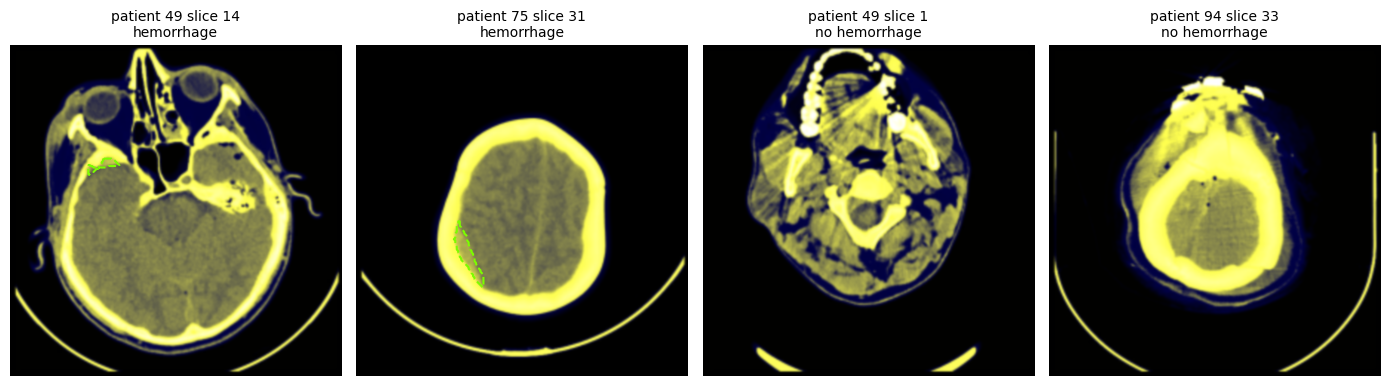

In [27]:
# ---------- 14.3 Load brain/bone JPGs and lesion masks for every slice ----------
CT_MODES = ("brain_brain_bone", "brain_x3")
PRIMARY_MODE = "brain_brain_bone"      # declared before looking at any CT-ICH result

def _read_gray(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(str(path))
    return img

def _load_ct_slice(args):
    pid, sno = args
    base = CTICH_DIR / "Patients_CT" / f"{int(pid):03d}"
    try:
        brain = cv2.resize(_read_gray(base / "brain" / f"{sno}.jpg"), (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        bone = cv2.resize(_read_gray(base / "bone" / f"{sno}.jpg"), (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        seg_path = base / "brain" / f"{sno}_HGE_Seg.jpg"
        if seg_path.exists():
            seg = (_read_gray(seg_path) > 128).astype(np.float32)
            seg = cv2.resize(seg, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA) >= 0.5
        else:
            seg = np.zeros((IMG_SIZE, IMG_SIZE), dtype=bool)
        return brain, bone, seg, None
    except Exception as exc:
        return None, None, None, repr(exc)

jobs = list(zip(ct["PatientID"].astype(int), ct["SliceNumber"].astype(int)))
with ThreadPoolExecutor(max_workers=NUM_WORKERS) as executor:
    loaded = list(tqdm(executor.map(_load_ct_slice, jobs), total=len(jobs), desc="Load CT-ICH slices"))

bad = [i for i, r in enumerate(loaded) if r[3] is not None]
# Known gap in archive v1.0.0: patient 084 has a label row for slice 36 but no bone/36.jpg.
# Such slices are dropped (here: one normal slice) and the labels are re-aligned below.
print("Slices that failed to load:", len(bad))
if bad:
    print(loaded[bad[0]][3])
    keep = [i for i in range(len(loaded)) if i not in set(bad)]
    loaded = [loaded[i] for i in keep]
    ct = ct.iloc[keep].reset_index(drop=True)
    ct_labels_arr = ct[LABEL_COLS].values.astype(np.float32)

ct_brain = np.stack([r[0] for r in loaded])      # (N, 224, 224) uint8, brain window as exported by the authors
ct_bone = np.stack([r[1] for r in loaded])       # (N, 224, 224) uint8, bone window
ct_masks = np.stack([r[2] for r in loaded])      # (N, 224, 224) bool, radiologist hemorrhage mask
del loaded
groups_ct = ct["PatientID"].values

has_mask = ct_masks.reshape(len(ct_masks), -1).any(axis=1)
print(f"Loaded {len(ct)} slices | slices with a mask: {int(has_mask.sum())} | any=1 slices: {int(ct['any'].sum())}")
print("Mask but any=0:", int((has_mask & (ct['any'] == 0)).sum()),
      "| any=1 but no mask:", int((~has_mask & (ct['any'] == 1)).sum()))

def make_ct_images(mode):
    """Approximate the RSNA 3-window input from the two 8-bit JPG renderings (see Part 14 rules)."""
    if mode == "brain_brain_bone":
        return np.stack([ct_brain, ct_brain, ct_bone], axis=-1)
    if mode == "brain_x3":
        return np.stack([ct_brain, ct_brain, ct_brain], axis=-1)
    raise ValueError(f"Unknown mode: {mode}")

def make_ct_image(i, mode=PRIMARY_MODE):
    """Single-slice version of make_ct_images (used for Grad-CAM and plots)."""
    if mode == "brain_brain_bone":
        return np.stack([ct_brain[i], ct_brain[i], ct_bone[i]], axis=-1)
    if mode == "brain_x3":
        return np.stack([ct_brain[i]] * 3, axis=-1)
    raise ValueError(f"Unknown mode: {mode}")

# Visual check: two hemorrhage slices (lesion outlined) and two normal slices.
pos_show = np.flatnonzero(has_mask)[[0, len(np.flatnonzero(has_mask)) // 2]]
neg_show = np.flatnonzero(~has_mask)[[0, len(np.flatnonzero(~has_mask)) // 2]]
fig, axes = plt.subplots(1, 4, figsize=(14, 4.4))
for ax, i in zip(axes, list(pos_show) + list(neg_show)):
    ax.imshow(make_ct_image(i), interpolation="bicubic")
    if has_mask[i]:
        ax.contour(ct_masks[i].astype(float), levels=[0.5], colors="#7CFC00", linewidths=1.5, linestyles="--")
    ax.set_title(f"patient {ct.loc[i, 'PatientID']} slice {ct.loc[i, 'SliceNumber']}\n"
                 + ("hemorrhage" if has_mask[i] else "no hemorrhage"), fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

**14.4 Metric helpers**

- **Patient-level bootstrap** confidence intervals (1000 resamples of patients).
- Sensitivity / specificity / PPV / NPV at a **fixed, previously chosen threshold**. On CT-ICH the prevalence is natural, so PPV and NPV here are *measured*, not estimated as in Part 9.
- **Scan-level aggregation** (one score per patient from its slices). This implements item 7 of Part 10, which the sampled RSNA subset could not support.

In [28]:
# ---------- 14.4 Metric helpers ----------
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

def _auc(y, s):
    y = np.asarray(y)
    return float(roc_auc_score(y, s)) if np.unique(y).size == 2 else np.nan

def _prauc(y, s):
    y = np.asarray(y)
    return float(average_precision_score(y, s)) if y.sum() > 0 else np.nan

def _div(a, b):
    return float(a / b) if b else np.nan

def patient_bootstrap_ci(y, s, groups, metric, n_boot=1000, seed=SEED):
    """95% percentile CI obtained by resampling whole patients (never single slices)."""
    y, s, groups = np.asarray(y), np.asarray(s), np.asarray(groups)
    by_patient = {g: np.flatnonzero(groups == g) for g in np.unique(groups)}
    keys = list(by_patient)
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(keys), len(keys))
        idx = np.concatenate([by_patient[keys[k]] for k in pick])
        v = metric(y[idx], s[idx])
        if np.isfinite(v):
            vals.append(v)
    if len(vals) < 0.5 * n_boot:          # too many resamples without both classes
        return np.nan, np.nan
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))

def operating_stats(y, s, thr):
    pred = np.asarray(s) >= thr
    y = np.asarray(y).astype(bool)
    tp, fn = int((pred & y).sum()), int((~pred & y).sum())
    fp, tn = int((pred & ~y).sum()), int((~pred & ~y).sum())
    return {"sens": _div(tp, tp + fn), "spec": _div(tn, tn + fp), "ppv": _div(tp, tp + fp),
            "npv": _div(tn, tn + fn), "TP": tp, "FN": fn, "FP": fp, "TN": tn}

def external_table(p, y, groups, thresholds, n_boot=1000):
    """Per-label external metrics at fixed thresholds. p, y: (N, 6) arrays in LABEL_COLS order."""
    patient_pos = (pd.DataFrame(y, columns=LABEL_COLS).assign(g=np.asarray(groups))
                   .groupby("g")[LABEL_COLS].max().sum())
    rows = []
    for j, name in enumerate(LABEL_COLS):
        lo, hi = patient_bootstrap_ci(y[:, j], p[:, j], groups, _auc, n_boot)
        rows.append({"label": name, "pos_slices": int(y[:, j].sum()), "pos_patients": int(patient_pos[name]),
                     "AUC": _auc(y[:, j], p[:, j]), "CI_low": lo, "CI_high": hi,
                     "PR_AUC": _prauc(y[:, j], p[:, j]), "prevalence": float(y[:, j].mean()),
                     "threshold": float(thresholds[j]), **operating_stats(y[:, j], p[:, j], thresholds[j]),
                     "enough_patients(>=10)": bool(patient_pos[name] >= 10)})
    return pd.DataFrame(rows).set_index("label")

def scan_level_report(p_any, y_any, groups, thr_any, k=3, n_boot=1000):
    """One score per patient: max over slices, or mean of the top-k slices."""
    df = pd.DataFrame({"g": np.asarray(groups), "p": np.asarray(p_any), "y": np.asarray(y_any)})
    agg = df.groupby("g").agg(y=("y", "max"), max_p=("p", "max"), topk=("p", lambda s: s.nlargest(k).mean()))
    rows = []
    for col, name in (("max_p", "max over slices"), ("topk", f"mean of top-{k} slices")):
        lo, hi = patient_bootstrap_ci(agg["y"].values, agg[col].values, agg.index.values, _auc, n_boot)
        st = operating_stats(agg["y"].values, agg[col].values, thr_any)
        rows.append({"aggregation": name, "patients": len(agg), "patients_with_ICH": int(agg["y"].sum()),
                     "AUC": _auc(agg["y"].values, agg[col].values), "CI_low": lo, "CI_high": hi,
                     "sens": st["sens"], "spec": st["spec"], "ppv": st["ppv"], "npv": st["npv"],
                     "FP_patients": st["FP"], "FN_patients": st["FN"]})
    return pd.DataFrame(rows).set_index("aggregation"), agg

**14.5 Run the frozen models on CT-ICH**

Both preprocessing modes are run. The **primary** result is `brain_brain_bone`, chosen before running; `brain_x3` is a robustness check. If the two disagree a lot, the preprocessing mismatch is a major part of the story and the numbers should not be read as a clean estimate of generalisation.

In [29]:
# ---------- 14.5 Predict on CT-ICH with the frozen RSNA models ----------
EXT_PROBS = {}
for mode in CT_MODES:
    imgs = make_ct_images(mode)
    loader = DataLoader(ICHDataset(imgs, ct_labels_arr, np.arange(len(imgs))), batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
    pa, y_ext = predict(model_A, loader)
    pb, _ = predict(model_B, loader)
    EXT_PROBS[mode] = {"Model A": pa, "Model B": pb, "Ensemble (A + B)": (pa + pb) / 2}
    del imgs, loader
assert np.allclose(y_ext, ct_labels_arr), "Prediction/label order mismatch"

# Thresholds are the validation-only ones from Part 9.1 (never re-fitted on CT-ICH).
thr_ens = np.asarray(DEMO_THRESHOLDS["Ensemble (A + B)"], dtype=float)
thr_youden = operating_table.loc[LABEL_COLS, "threshold_from_validation"].to_numpy(dtype=float)
p_primary = EXT_PROBS[PRIMARY_MODE]["Ensemble (A + B)"]

print(f"Primary mode: {PRIMARY_MODE} | model: Ensemble (A + B) | thresholds: validation, target >=90% sensitivity")
ens_table = external_table(p_primary, ct_labels_arr, groups_ct, thr_ens)
display(ens_table.round(3))

print("\nAUC comparison (same frozen models; only the data changes):")
cmp = pd.DataFrame({"RSNA_test_ensemble": auc_table["test_ensemble"]})
cmp["CTICH_ens_primary"] = [_auc(ct_labels_arr[:, j], EXT_PROBS[PRIMARY_MODE]["Ensemble (A + B)"][:, j]) for j in range(6)]
cmp["CTICH_ens_brain_x3"] = [_auc(ct_labels_arr[:, j], EXT_PROBS["brain_x3"]["Ensemble (A + B)"][:, j]) for j in range(6)]
cmp["CTICH_A_primary"] = [_auc(ct_labels_arr[:, j], EXT_PROBS[PRIMARY_MODE]["Model A"][:, j]) for j in range(6)]
cmp["CTICH_B_primary"] = [_auc(ct_labels_arr[:, j], EXT_PROBS[PRIMARY_MODE]["Model B"][:, j]) for j in range(6)]
cmp["CTICH_pos_patients"] = ens_table["pos_patients"]
display(cmp.round(3))

print("\nSecond operating point (Youden threshold from RSNA validation, still frozen):")
display(external_table(p_primary, ct_labels_arr, groups_ct, thr_youden, n_boot=200)
        [["threshold", "sens", "spec", "ppv", "npv", "FP", "FN"]].round(3))

print("\nScan-level (per patient) 'any hemorrhage', using the same frozen slice-level threshold:")
scan_tbl, scan_agg = scan_level_report(p_primary[:, 0], ct_labels_arr[:, 0], groups_ct, thr_ens[0])
display(scan_tbl.round(3))
print("Reading guide: with about 30 slices per scan, 'max over slices' accumulates false alarms; a threshold chosen for single "
      "slices is not the right one for scan decisions. Mean of top-k is less sensitive to one noisy slice. Do not re-tune on these 82 scans.")

ens_table.to_csv(OUT_DIR / "ctich_external_results.csv")
scan_tbl.to_csv(OUT_DIR / "ctich_scan_level_results.csv")
cmp.to_csv(OUT_DIR / "ctich_auc_comparison.csv")

Primary mode: brain_brain_bone | model: Ensemble (A + B) | thresholds: validation, target >=90% sensitivity


,pos_slices,pos_patients,AUC,CI_low,CI_high,PR_AUC,prevalence,threshold,sens,spec,ppv,npv,TP,FN,FP,TN,enough_patients(>=10)
label,,,,,,,,,,,,,,,,,
any,318,36,0.907,0.877,0.933,0.594,0.127,0.432,0.321,0.983,0.729,0.908,102,216,38,2144,True
epidural,173,21,0.817,0.765,0.860,0.243,0.069,0.106,0.214,0.961,0.289,0.943,37,136,91,2236,True
intraparenchymal,73,16,0.936,0.901,0.962,0.337,0.029,0.083,0.205,0.988,0.341,0.976,15,58,29,2398,True
intraventricular,24,5,0.977,0.928,0.994,0.575,0.010,0.104,0.375,0.999,0.818,0.994,9,15,2,2474,False
subarachnoid,18,7,0.885,0.734,0.959,0.085,0.007,0.053,0.778,0.818,0.030,0.998,14,4,451,2031,False
subdural,56,4,0.913,0.862,0.954,0.165,0.022,0.110,0.875,0.850,0.118,0.997,49,7,367,2077,False



AUC comparison (same frozen models; only the data changes):


,RSNA_test_ensemble,CTICH_ens_primary,CTICH_ens_brain_x3,CTICH_A_primary,CTICH_B_primary,CTICH_pos_patients
any,0.960,0.907,0.793,0.887,0.885,36
epidural,0.932,0.817,0.647,0.807,0.801,21
intraparenchymal,0.957,0.936,0.853,0.922,0.894,16
intraventricular,0.963,0.977,0.923,0.968,0.958,5
subarachnoid,0.886,0.885,0.831,0.885,0.861,7
subdural,0.886,0.913,0.842,0.893,0.882,4



Second operating point (Youden threshold from RSNA validation, still frozen):


,threshold,sens,spec,ppv,npv,FP,FN
label,,,,,,,
any,0.461,0.252,0.985,0.714,0.900,32,238
epidural,0.113,0.202,0.968,0.321,0.942,74,138
intraparenchymal,0.079,0.219,0.986,0.314,0.977,35,57
intraventricular,0.179,0.333,1.000,1.000,0.994,0,16
subarachnoid,0.138,0.556,0.964,0.100,0.997,90,8
subdural,0.164,0.661,0.935,0.190,0.992,158,19



Scan-level (per patient) 'any hemorrhage', using the same frozen slice-level threshold:


,patients,patients_with_ICH,AUC,CI_low,CI_high,sens,spec,ppv,npv,FP_patients,FN_patients
aggregation,,,,,,,,,,,
max over slices,82,36,0.900,0.819,0.963,0.639,0.957,0.92,0.772,2,13
mean of top-3 slices,82,36,0.916,0.848,0.970,0.556,1.000,1.00,0.742,0,16


Reading guide: with about 30 slices per scan, 'max over slices' accumulates false alarms; a threshold chosen for single slices is not the right one for scan decisions. Mean of top-k is less sensitive to one noisy slice. Do not re-tune on these 82 scans.


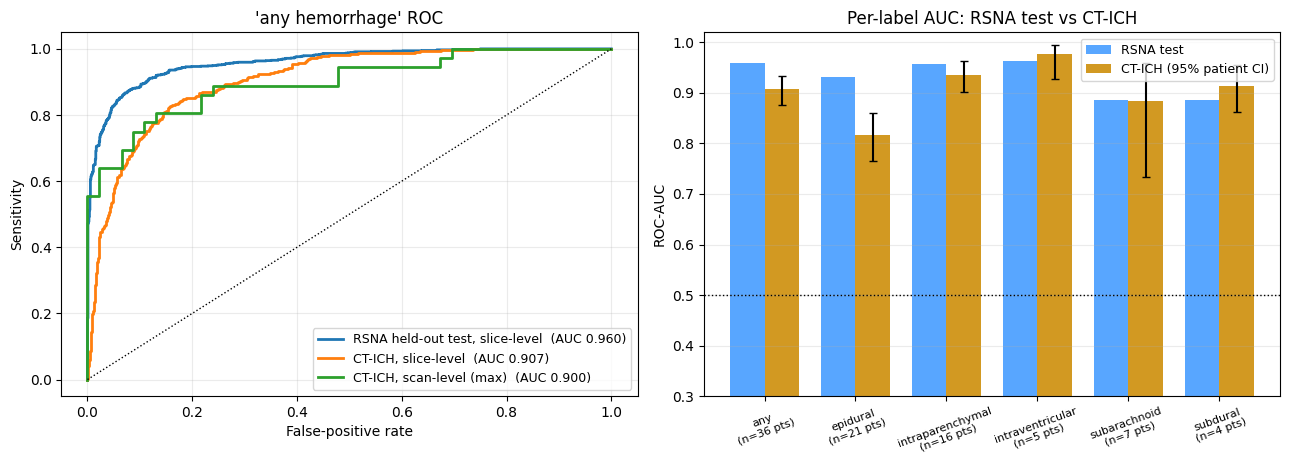

In [30]:
# ---------- 14.6 Plots: ROC and per-label AUC with patient-level CIs ----------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

ax = axes[0]
curves = {
    "RSNA held-out test, slice-level": (tt[:, 0], pt_ens[:, 0]),
    "CT-ICH, slice-level": (ct_labels_arr[:, 0], p_primary[:, 0]),
    "CT-ICH, scan-level (max)": (scan_agg["y"].values, scan_agg["max_p"].values),
}
for name, (yy, ss) in curves.items():
    fpr, tpr, _ = roc_curve(yy, ss)
    ax.plot(fpr, tpr, lw=2, label=f"{name}  (AUC {_auc(yy, ss):.3f})")
ax.plot([0, 1], [0, 1], "k:", lw=1)
ax.set_xlabel("False-positive rate"); ax.set_ylabel("Sensitivity"); ax.set_title("'any hemorrhage' ROC")
ax.legend(loc="lower right", fontsize=9); ax.grid(alpha=0.25)

ax = axes[1]
x = np.arange(len(LABEL_COLS)); w = 0.38
ax.bar(x - w / 2, auc_table["test_ensemble"].values, w, label="RSNA test", color="#58a6ff")
yerr = np.vstack([np.nan_to_num(ens_table["AUC"] - ens_table["CI_low"]),
                  np.nan_to_num(ens_table["CI_high"] - ens_table["AUC"])])
ax.bar(x + w / 2, np.nan_to_num(ens_table["AUC"].values), w, yerr=yerr, capsize=3, label="CT-ICH (95% patient CI)", color="#d29922")
ax.set_xticks(x)
ax.set_xticklabels([f"{c}\n(n={int(n)} pts)" for c, n in zip(LABEL_COLS, ens_table["pos_patients"])], fontsize=8, rotation=20)
ax.axhline(0.5, color="k", ls=":", lw=1)
ax.set_ylim(0.3, 1.02); ax.set_ylabel("ROC-AUC"); ax.set_title("Per-label AUC: RSNA test vs CT-ICH")
ax.legend(fontsize=9); ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## Part 15: Does Grad-CAM point at the real lesion? (CT-ICH masks)

Part 12.2 warns that Grad-CAM is a coarse attention map and not a segmentation. The CT-ICH masks let us **measure** how well the "any hemorrhage" Grad-CAM overlaps the radiologists' outline, on slices that truly contain a bleed. (The synthetic phantoms in Part 12.1 have masks too, but they are artificial; these are real.)

Metrics per slice (Grad-CAM from the ensemble, target `any`):
- **Peak in lesion:** the single hottest pixel falls inside the mask (strict) or within `POINTING_TOLERANCE_PX` of it. The Grad-CAM grid of ResNet-50 is 7x7 (one cell = 32 px at 224 px), so a 16 px tolerance is half a cell.
- **CAM mass in lesion / enrichment:** share of total Grad-CAM energy inside the mask, and that share divided by the lesion's share of the image area (1 = no better than chance relative to the whole frame; the baseline is rough because the head does not fill the frame).
- **Dice / IoU** of the CAM thresholded at `CAM_BINARIZE_FRACTION` of its maximum. Expect low values: a 7x7 map cannot match thin crescents such as epidural/subdural bleeds. Use it to compare runs, not as a segmentation score.

The metrics are reported for all lesion slices and for the slices the model actually **detected** (score above the frozen threshold), because an explanation of a missed bleed is not meaningful. Subtype rows overlap when a slice has several subtypes, and several subtypes have very few patients.

Grad-CAM on lesion slices:   0%|          | 0/318 [00:00<?, ?it/s]

,slices,patients,peak_in_lesion,peak_within_16px,median_CAM_mass_in_lesion,median_enrichment,median_Dice
all lesion slices,318.0,36.0,0.057,0.296,0.008,2.530,0.007
detected lesion slices,102.0,21.0,0.029,0.480,0.019,4.050,0.062
epidural (detected),37.0,9.0,0.027,0.595,0.035,5.615,0.077
intraparenchymal (detected),37.0,9.0,0.054,0.378,0.015,3.512,0.025
intraventricular (detected),13.0,3.0,0.154,0.615,0.019,3.191,0.040
subarachnoid (detected),12.0,5.0,0.083,0.333,0.009,1.998,0.000
subdural (detected),17.0,4.0,0.000,0.588,0.043,3.152,0.102


Detected 102 of 318 lesion slices at the frozen 'any' threshold (0.432) - this is slice-level sensitivity on CT-ICH.


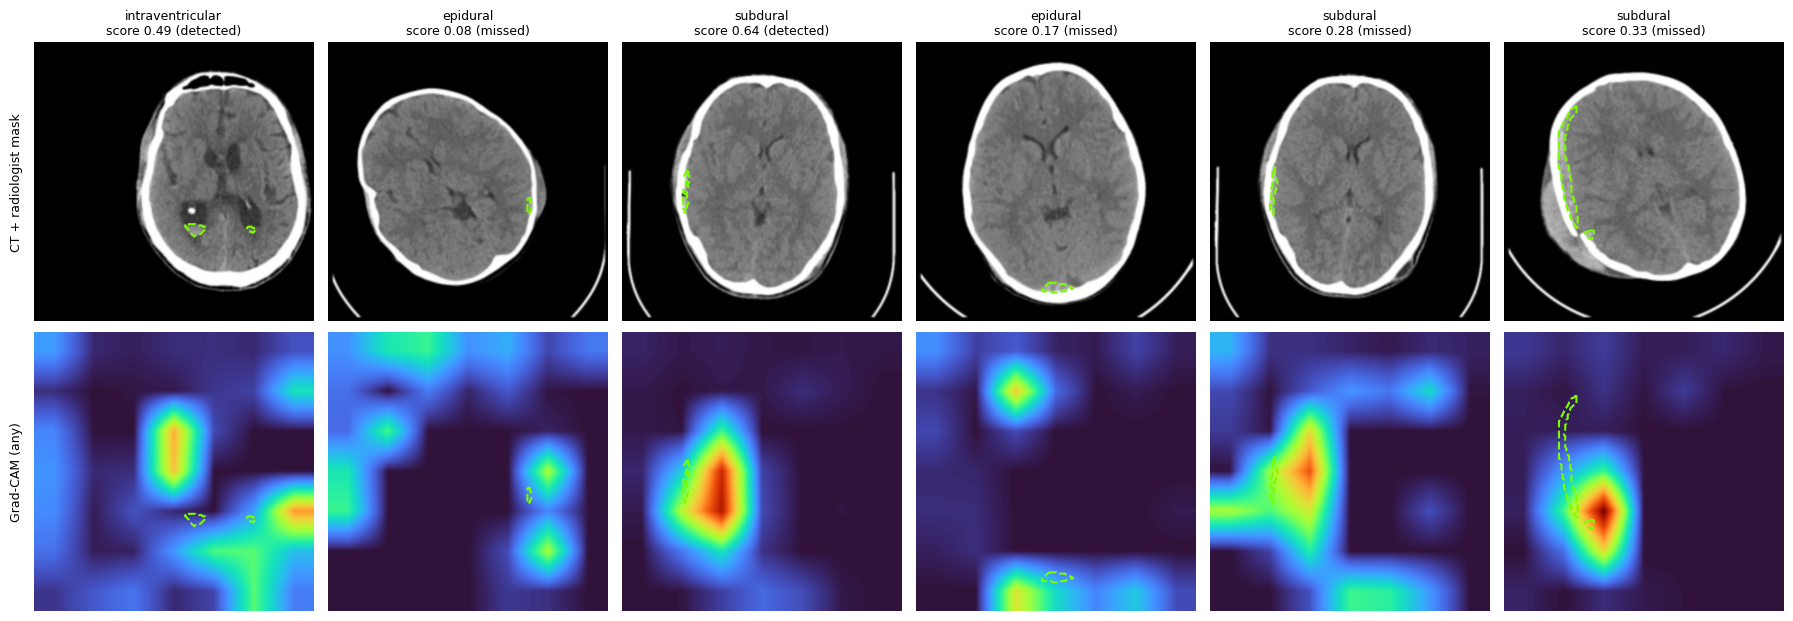

In [31]:
# ---------- 15.1 Grad-CAM vs radiologist masks ----------
POINTING_TOLERANCE_PX = 16
CAM_BINARIZE_FRACTION = 0.5

def cam_mask_metrics(cam, mask, tol=POINTING_TOLERANCE_PX, frac=CAM_BINARIZE_FRACTION):
    """cam: (H, W) float in [0, 1]; mask: (H, W) bool, non-empty."""
    cam = np.asarray(cam, dtype=np.float32)
    mask = np.asarray(mask).astype(bool)
    peak = np.unravel_index(int(np.argmax(cam)), cam.shape)
    k = 2 * tol + 1
    grown = cv2.dilate(mask.astype(np.uint8), cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))).astype(bool)
    mass = float((cam * mask).sum() / (cam.sum() + 1e-8))
    area = float(mask.mean())
    pred = cam >= frac * cam.max()
    inter = float((pred & mask).sum())
    union = float((pred | mask).sum())
    return {"hit_strict": bool(mask[peak]), "hit_tol": bool(grown[peak]),
            "cam_mass_in_mask": mass, "lesion_area_frac": area, "enrichment": mass / max(area, 1e-8),
            "iou": inter / union if union else np.nan,
            "dice": 2 * inter / (pred.sum() + mask.sum()) if (pred.sum() + mask.sum()) else np.nan}

lesion_idx = np.flatnonzero(has_mask)
rows, cam_store = [], {}
for i in tqdm(lesion_idx, desc="Grad-CAM on lesion slices"):
    probs, cam, _ = infer(make_ct_image(i, PRIMARY_MODE), "Ensemble (A + B)", "any")
    rows.append({"idx": int(i), "PatientID": ct.loc[i, "PatientID"], "p_any": float(probs[0]),
                 "detected": bool(probs[0] >= thr_ens[0]),
                 **{c: int(ct.loc[i, c]) for c in LABEL_COLS[1:]},
                 **cam_mask_metrics(cam, ct_masks[i])})
    cam_store[int(i)] = np.asarray(cam, dtype=np.float32)
loc = pd.DataFrame(rows)

def _summ(df):
    return pd.Series({"slices": len(df), "patients": df["PatientID"].nunique(),
                      "peak_in_lesion": df["hit_strict"].mean(),
                      f"peak_within_{POINTING_TOLERANCE_PX}px": df["hit_tol"].mean(),
                      "median_CAM_mass_in_lesion": df["cam_mass_in_mask"].median(),
                      "median_enrichment": df["enrichment"].median(),
                      "median_Dice": df["dice"].median()})

groups_loc = {"all lesion slices": loc, "detected lesion slices": loc[loc["detected"]]}
for lab in LABEL_COLS[1:]:
    groups_loc[f"{lab} (detected)"] = loc[(loc[lab] == 1) & loc["detected"]]
loc_summary = pd.DataFrame({k: _summ(v) for k, v in groups_loc.items() if len(v)}).T
display(loc_summary.round(3))
print(f"Detected {int(loc['detected'].sum())} of {len(loc)} lesion slices at the frozen 'any' threshold "
      f"({thr_ens[0]:.3f}) - this is slice-level sensitivity on CT-ICH.")
loc.to_csv(OUT_DIR / "ctich_localization.csv", index=False)

# Gallery of random lesion slices (not cherry-picked: fixed seed).
rng = np.random.default_rng(SEED)
show = rng.choice(loc["idx"].values, size=min(6, len(loc)), replace=False)
fig, axes = plt.subplots(2, len(show), figsize=(3.0 * len(show), 6.4), squeeze=False)
for col, i in enumerate(show):
    r = loc.loc[loc["idx"] == i].iloc[0]
    kinds = [c for c in LABEL_COLS[1:] if r[c] == 1]
    img = make_ct_image(i, PRIMARY_MODE)
    axes[0, col].imshow(img[..., 0], cmap="gray", vmin=0, vmax=255, interpolation="bicubic")
    axes[0, col].set_title(f"{', '.join(kinds)}\nscore {r['p_any']:.2f} {'(detected)' if r['detected'] else '(missed)'}", fontsize=9)
    axes[1, col].imshow(img[..., 0], cmap="gray", vmin=0, vmax=255, interpolation="bicubic")
    cam = cam_store[int(i)]
    axes[1, col].imshow(cam, cmap="turbo", alpha=np.clip(cam * 1.25, 0, 0.75), interpolation="bicubic", vmin=0, vmax=1)
    for row_ax in (axes[0, col], axes[1, col]):
        row_ax.contour(ct_masks[i].astype(float), levels=[0.5], colors="#7CFC00", linewidths=1.5, linestyles="--")
        row_ax.axis("off")
axes[0, 0].text(-0.04, 0.5, "CT + radiologist mask", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right", fontsize=9)
axes[1, 0].text(-0.04, 0.5, "Grad-CAM (any)", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right", fontsize=9)
plt.tight_layout()
plt.show()

## Part 16: What Parts 14-15 do and do not show

**They show** how the frozen RSNA-trained ensemble behaves on an independent, fully sliced, naturally distributed head-CT set from another hospital, at thresholds chosen without looking at it, with patient-level uncertainty; whether scan-level aggregation helps; and how well Grad-CAM overlaps real radiologist masks.

**They do not show** clinical performance:
- 82 scans (36 with hemorrhage) from one hospital; several subtypes have fewer than 10 patients, so their AUCs are anecdotal.
- The inputs are 8-bit JPG renderings, not DICOM/HU, so the RSNA windowing could not be reproduced exactly; domain shift and preprocessing mismatch are confounded (compare the two modes).
- The population is young and trauma-heavy, which differs from the RSNA mix.
- Thresholds from RSNA validation need not transfer; if sensitivity/specificity move a lot, that is a finding, not something to fix by re-tuning on these 82 scans and then reporting the result as "external".

**Not included (needs a GPU run, not a notebook edit):** a segmentation model (U-Net) trained on the CT-ICH masks, which is what the archive's own `split_data.py` was preparing data for. If you add it, split **by patient** (e.g. 5-fold `GroupKFold` on `PatientID`), because neighbouring slices of one patient are nearly identical.